In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning) 

### loading the meta data

In [4]:
dataset = pd.read_csv('labels.csv')

### data set information

In [5]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16266 entries, 0 to 16265
Data columns (total 34 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   image_id                  16266 non-null  object 
 1   patient_id                16266 non-null  int64  
 2   camera                    16266 non-null  object 
 3   patient_age               10821 non-null  float64
 4   comorbidities             8030 non-null   object 
 5   diabetes_time_y           1910 non-null   object 
 6   insuline                  1714 non-null   object 
 7   patient_sex               16266 non-null  int64  
 8   exam_eye                  16266 non-null  int64  
 9   diabetes                  16266 non-null  object 
 10  nationality               16266 non-null  object 
 11  optic_disc                16266 non-null  object 
 12  vessels                   16266 non-null  int64  
 13  macula                    16266 non-null  int64  
 14  DR_SDR

In [6]:
dataset.head()

,image_id,patient_id,camera,patient_age,comorbidities,diabetes_time_y,insuline,patient_sex,exam_eye,diabetes,...,amd,vascular_occlusion,hypertensive_retinopathy,drusens,hemorrhage,retinal_detachment,myopic_fundus,increased_cup_disc,other,quality
0,img00001,1,Canon CR,48.0,diabetes1,12,yes,1,1,yes,...,0,0,0,0,0,0,0,1,0,Adequate
1,img00002,1,Canon CR,48.0,diabetes1,12,yes,1,2,yes,...,0,0,0,0,0,0,0,1,0,Adequate
2,img00003,2,Canon CR,18.0,diabetes1,7,yes,2,1,yes,...,0,0,0,0,0,0,0,0,0,Adequate
3,img00004,2,Canon CR,18.0,diabetes1,7,yes,2,2,yes,...,0,0,0,0,0,0,0,0,0,Adequate
4,img00005,3,Canon CR,22.0,diabetes1,11,yes,1,1,yes,...,0,0,0,0,0,0,0,0,0,Adequate


### checking categorical columns

In [7]:
dataset.select_dtypes(include=['object']).columns

Index(['image_id', 'camera', 'comorbidities', 'diabetes_time_y', 'insuline',
       'diabetes', 'nationality', 'optic_disc', 'quality'],
      dtype='object')

In [8]:
unique_values = []

for i in dataset.select_dtypes(include=['object']).columns:
    print(dataset[i].unique())


['img00001' 'img00002' 'img00003' ... 'img16264' 'img16265' 'img16266']
['Canon CR' 'NIKON NF5050']
['diabetes1' 'diabetes1, SAH' 'diabetes, SAH' 'dyslipidemia' 'SAH'
 'acute myocardium infarct, encephalic vascular accident' nan '0'
 'hyperthyroidism' 'cerebral palsy' 'diabetes'
 'human immunodeficiency virus' 'encephalic vascular accident'
 'diabetes, dyslipidemia, hypothyroidism' 'hypothyroidism'
 'SAH, hypothyroidism' 'asthma' 'lupus' 'parkinson' 'rhinitis'
 'diabetes, arrhythmia' 'rheumatoid arthritis' 'SAH, rheumatoid arthritis'
 'migraine' 'diabetes, SAH, hypothyroidism' 'SAH, alzheimer'
 'SAH, dyslipidemia' 'diabetes, SAH, tabagism'
 'hypothyroidism, hypophysis adenoma' 'syphilis' 'arthrosis'
 'SAH, cardiac insufficiency' 'SAH, arthritis' 'acute myocardium infarct'
 'sickle cell anemia, thalassemia' 'SAH, chagas' 'cardiopathy' 'epilepsy'
 'herpetic encephalitis' 'diabetes, SAH, dialysis'
 'rheumatoid arthritis, hydroxychloroquine' 'SAH, arrhythmia'
 'sickle cell anemia' 'hyperch

### checking missing values

In [9]:
print(dataset.isnull().sum()*100/len(dataset))

image_id                     0.000000
patient_id                   0.000000
camera                       0.000000
patient_age                 33.474733
comorbidities               50.633223
diabetes_time_y             88.257715
insuline                    89.462683
patient_sex                  0.000000
exam_eye                     0.000000
diabetes                     0.000000
nationality                  0.000000
optic_disc                   0.000000
vessels                      0.000000
macula                       0.000000
DR_SDRG                      0.000000
DR_ICDR                      0.000000
focus                        0.000000
iluminaton                   0.000000
image_field                  0.000000
artifacts                    0.000000
diabetic_retinopathy         0.000000
macular_edema                0.000000
scar                         0.000000
nevus                        0.000000
amd                          0.000000
vascular_occlusion           0.000000
hypertensive

### Data Pre Processing

In [10]:
# Handling missing values for patient_age by filling with median
dataset['patient_age'].fillna(dataset['patient_age'].median(), inplace=True)

# Replacing 'bv' in optic_disc with the mode value
dataset['optic_disc'].replace('bv', dataset['optic_disc'].mode()[0], inplace=True)

# Converting the relevant columns to integers
dataset['optic_disc'] = dataset['optic_disc'].astype(int)

# Creating 'quality_eye' column
dataset['quality_eye'] = dataset.apply(lambda x: 'abnormal' if (x[['focus', 'iluminaton', 'image_field', 'artifacts']] == 2).sum() > 2 else 'normal', axis=1)

# Creating 'eye_normality' column
classification_columns = ['diabetic_retinopathy', 'macular_edema', 'scar', 'nevus', 'amd', 
                          'vascular_occlusion', 'hypertensive_retinopathy', 'drusens', 
                          'hemorrhage', 'retinal_detachment', 'myopic_fundus', 'increased_cup_disc', 'other']

dataset['eye_normality'] = dataset.apply(lambda x: 'abnormal' if (x[classification_columns] != 0).sum() > 0 else 'normal', axis=1)

# Creating 'eye_anatomy' column
anatomical_columns = ['optic_disc', 'vessels', 'macula']

dataset['eye_anatomy'] = dataset.apply(lambda x: 'abnormal' if (x[anatomical_columns] == 2).sum() > 2 else 'normal', axis=1)

# Display the first few rows to verify the changes
dataset[['quality_eye', 'eye_normality', 'eye_anatomy']].head(10)


/var/folders/pq/hgtzyqxj0wv3fdyrkjnnl35c0000gp/T/ipykernel_924/1362154013.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  dataset['patient_age'].fillna(dataset['patient_age'].median(), inplace=True)
/var/folders/pq/hgtzyqxj0wv3fdyrkjnnl35c0000gp/T/ipykernel_924/1362154013.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we

,quality_eye,eye_normality,eye_anatomy
0,normal,abnormal,normal
1,normal,abnormal,normal
2,normal,normal,normal
3,normal,normal,normal
4,normal,normal,normal
5,normal,normal,normal
6,normal,normal,normal
7,normal,normal,normal
8,normal,normal,normal
9,normal,normal,normal


/var/folders/pq/hgtzyqxj0wv3fdyrkjnnl35c0000gp/T/ipykernel_924/3003849462.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='quality_eye', data=dataset, palette="viridis")
/var/folders/pq/hgtzyqxj0wv3fdyrkjnnl35c0000gp/T/ipykernel_924/3003849462.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='eye_normality', data=dataset, palette="viridis")
/var/folders/pq/hgtzyqxj0wv3fdyrkjnnl35c0000gp/T/ipykernel_924/3003849462.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='eye_anatomy', data=dataset, palette="viridis")


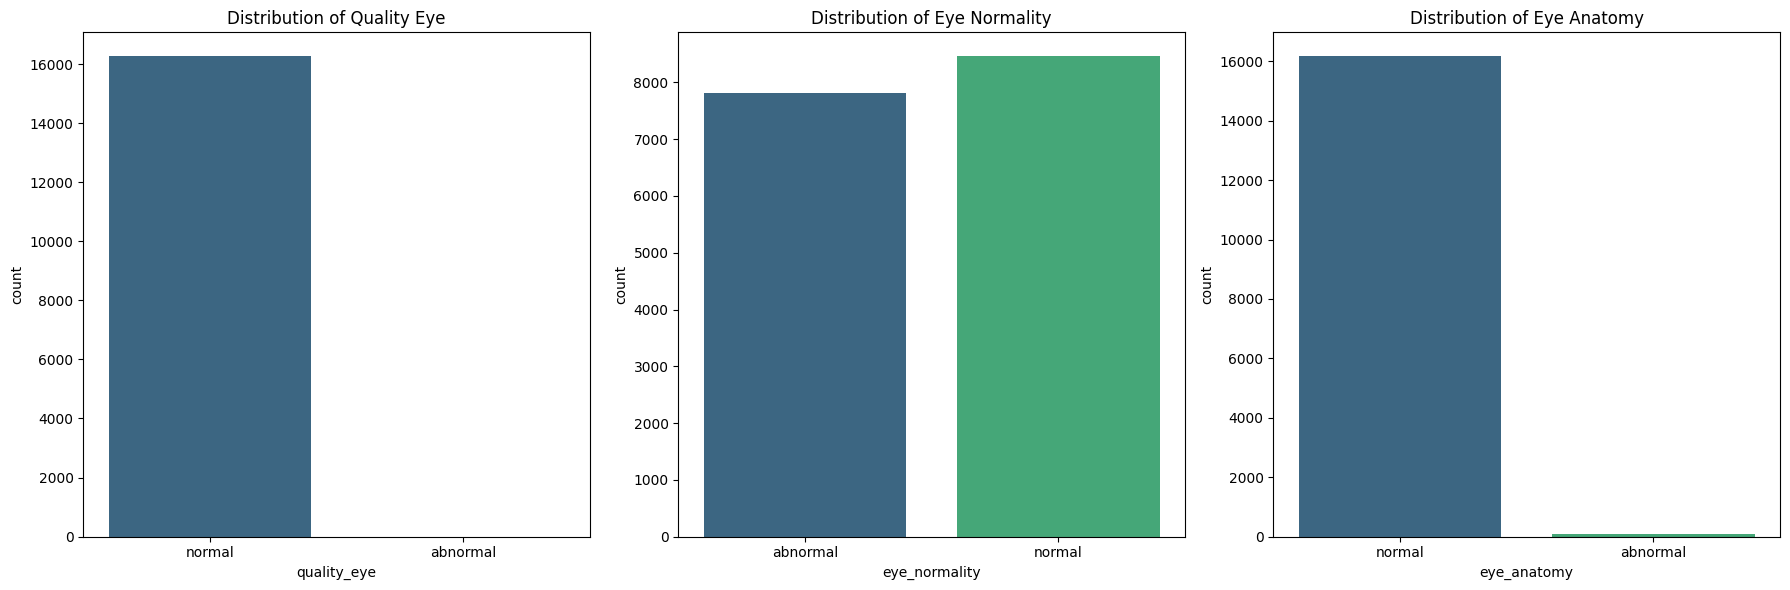

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set up the matplotlib figure
plt.figure(figsize=(18, 6))

# Plotting the distribution of quality_eye
plt.subplot(1, 3, 1)
sns.countplot(x='quality_eye', data=dataset, palette="viridis")
plt.title('Distribution of Quality Eye')

# Plotting the distribution of eye_normality
plt.subplot(1, 3, 2)
sns.countplot(x='eye_normality', data=dataset, palette="viridis")
plt.title('Distribution of Eye Normality')


# Plotting the distribution of quality
plt.subplot(1, 3, 3)
sns.countplot(x='eye_anatomy', data=dataset, palette="viridis")
plt.title('Distribution of Eye Anatomy')


plt.tight_layout()
plt.show()




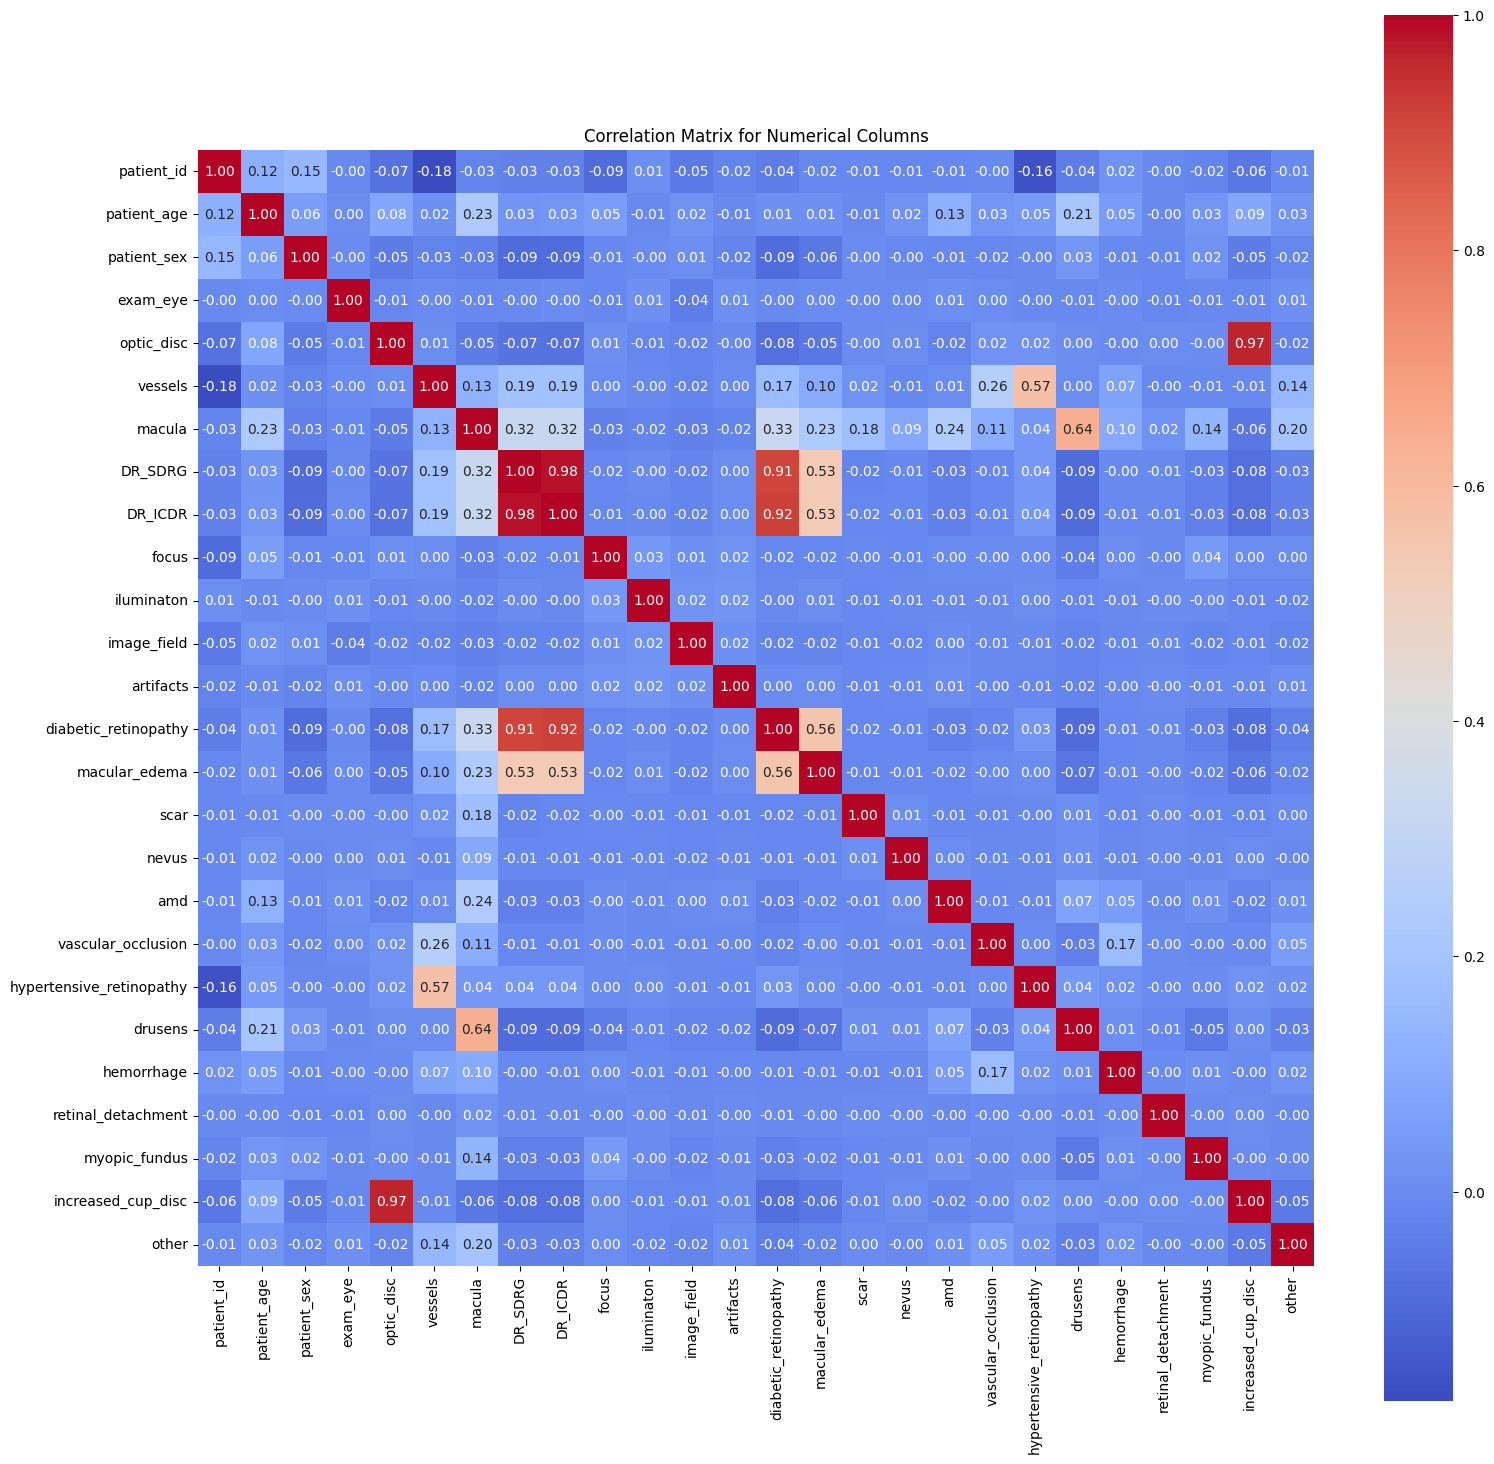

In [12]:
numerical_columns = dataset.select_dtypes(include=['int64', 'float64']).columns

# Calculating correlation matrix
corr_matrix = dataset[numerical_columns].corr()

# Plotting the heatmap
plt.figure(figsize=(18, 18))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True, square=True)
plt.title('Correlation Matrix for Numerical Columns')
plt.show()

### checking and alter the comorbidities column

In [13]:
# Step 1: Standardize Text
dataset['comorbidities'] = dataset['comorbidities'].str.lower().str.strip()

# Step 2: Replace Common Abbreviations/Synonyms
replacement_dict = {
    'sah': 'systemic arterial hypertension',
    'dm': 'diabetes mellitus',
    'cvd': 'cardiovascular disease',
    'htn': 'hypertension',
    'mi': 'myocardial infarction',
    # Add more replacements as needed
}

dataset['comorbidities'] = dataset['comorbidities'].replace(replacement_dict, regex=True)

# Step 3: Split the conditions into lists
dataset['comorbidities'] = dataset['comorbidities'].str.split(',')

# Step 4: Remove duplicates within each patient's comorbidities list
dataset['comorbidities'] = dataset['comorbidities'].apply(lambda x: list(set(x)) if isinstance(x, list) else x)

# Step 5: Analyze the unique comorbidities
# Exploding the list of comorbidities to analyze individual conditions
comorbidities_exploded = dataset.explode('comorbidities')

# Count frequency of each comorbidity
comorbidity_counts = comorbidities_exploded['comorbidities'].value_counts()

# Display the most common comorbidities
comorbidity_counts.head(10)


comorbidities
0                                                    2766
diabetes                                             2120
systemic arterial hypertension                       1953
 systemic arterial hypertension                      1224
diabetes1                                             429
 hypothyroidism                                       144
hypothyroidism                                        142
systemyocardial infarctionc arterial hypertension      86
 hypercholesterolemyocardial infarctiona               72
 dyslipidemyocardial infarctiona                       72
Name: count, dtype: int64

### changing the comorbidities column to diabetes realted column

In [14]:
diabetes_related_terms = ['diabetes', 'diabetes mellitus', 'diabetes1']

# Ensure that all entries in the 'comorbidities' column are lists, and fill any missing values with an empty list
dataset['comorbidities'] = dataset['comorbidities'].apply(lambda x: x if isinstance(x, list) else [])

# Create a new binary column 'has_diabetes' based on the presence of diabetes-related terms
dataset['has_diabetes'] = dataset['comorbidities'].apply(
    lambda x: 1 if any(term in x for term in diabetes_related_terms) else 0
)

# Display the first few rows to verify
dataset['has_diabetes'].unique()


array([1, 0])

In [15]:
dataset.columns

Index(['image_id', 'patient_id', 'camera', 'patient_age', 'comorbidities',
       'diabetes_time_y', 'insuline', 'patient_sex', 'exam_eye', 'diabetes',
       'nationality', 'optic_disc', 'vessels', 'macula', 'DR_SDRG', 'DR_ICDR',
       'focus', 'iluminaton', 'image_field', 'artifacts',
       'diabetic_retinopathy', 'macular_edema', 'scar', 'nevus', 'amd',
       'vascular_occlusion', 'hypertensive_retinopathy', 'drusens',
       'hemorrhage', 'retinal_detachment', 'myopic_fundus',
       'increased_cup_disc', 'other', 'quality', 'quality_eye',
       'eye_normality', 'eye_anatomy', 'has_diabetes'],
      dtype='object')

### droping unnecessary column and label ecoding to categorical to numerical columns

In [16]:
from sklearn.preprocessing import LabelEncoder
# Dropping the specified columns
columns_to_drop_specific = [
    'camera', 'comorbidities', 'diabetes_time_y', 'insuline', 'exam_eye', 'nationality',
    'optic_disc', 'vessels', 'macula', 'DR_SDRG', 'focus', 'iluminaton', 
    'image_field', 'artifacts'
]

df_final_specific = dataset.drop(columns=columns_to_drop_specific)

# Label encoding for 'eye_quality', 'eye_anatomy', and 'eye_normality'
label_encoder = LabelEncoder()

df_final_specific['eye_quality_encoded'] = label_encoder.fit_transform(df_final_specific['quality_eye'])
df_final_specific['eye_anatomy_encoded'] = label_encoder.fit_transform(df_final_specific['eye_anatomy'])
df_final_specific['eye_normality_encoded'] = label_encoder.fit_transform(df_final_specific['eye_normality'])

# Dropping the original 'quality_eye', 'eye_anatomy', and 'eye_normality' columns after encoding
df_final_specific.drop(columns=['quality_eye', 'eye_anatomy', 'eye_normality'], inplace=True)

# Display the first few rows to verify
df_final_specific.head(10)


,image_id,patient_id,patient_age,patient_sex,diabetes,DR_ICDR,diabetic_retinopathy,macular_edema,scar,nevus,...,hemorrhage,retinal_detachment,myopic_fundus,increased_cup_disc,other,quality,has_diabetes,eye_quality_encoded,eye_anatomy_encoded,eye_normality_encoded
0,img00001,1,48.0,1,yes,0,0,0,0,0,...,0,0,0,1,0,Adequate,1,1,1,0
1,img00002,1,48.0,1,yes,0,0,0,0,0,...,0,0,0,1,0,Adequate,1,1,1,0
2,img00003,2,18.0,2,yes,0,0,0,0,0,...,0,0,0,0,0,Adequate,1,1,1,1
3,img00004,2,18.0,2,yes,0,0,0,0,0,...,0,0,0,0,0,Adequate,1,1,1,1
4,img00005,3,22.0,1,yes,0,0,0,0,0,...,0,0,0,0,0,Adequate,1,1,1,1
5,img00006,3,22.0,1,yes,0,0,0,0,0,...,0,0,0,0,0,Adequate,1,1,1,1
6,img00007,4,22.0,1,yes,0,0,0,0,0,...,0,0,0,0,0,Adequate,1,1,1,1
7,img00008,4,22.0,1,yes,0,0,0,0,0,...,0,0,0,0,0,Adequate,1,1,1,1
8,img00009,5,23.0,1,yes,0,0,0,0,0,...,0,0,0,0,0,Adequate,1,1,1,1
9,img00010,5,23.0,1,yes,0,0,0,0,0,...,0,0,0,0,0,Adequate,1,1,1,1


### checking the values count targeting columns

In [17]:
print(df_final_specific['DR_ICDR'].value_counts())
print(df_final_specific['diabetes'].value_counts())
print(df_final_specific['DR_ICDR'].dtype)

DR_ICDR
0    15210
4      394
2      310
3      190
1      162
Name: count, dtype: int64
diabetes
no     13687
yes     2579
Name: count, dtype: int64
int64


### converting diabetes and DR_ICDR into numerical column and converting all the column to numerical

In [18]:
# Convert 'diabetes' column to binary format (1 for 'yes', 0 for 'no')
df_final_specific['diabetes'] = df_final_specific['diabetes'].apply(lambda x: 1 if x == 'yes' else 0)
df_final_specific['DR_ICDR'] = df_final_specific['DR_ICDR'].apply(lambda x: 0 if x==0 else 1)
# Now, convert all columns except 'image_id' and 'quality' to integer type
columns_to_convert = df_final_specific.columns.difference(['image_id', 'quality'])

df_final_specific[columns_to_convert] = df_final_specific[columns_to_convert].astype(int)

# Verify the changes
df_final_specific.dtypes


image_id                    object
patient_id                   int64
patient_age                  int64
patient_sex                  int64
diabetes                     int64
DR_ICDR                      int64
diabetic_retinopathy         int64
macular_edema                int64
scar                         int64
nevus                        int64
amd                          int64
vascular_occlusion           int64
hypertensive_retinopathy     int64
drusens                      int64
hemorrhage                   int64
retinal_detachment           int64
myopic_fundus                int64
increased_cup_disc           int64
other                        int64
quality                     object
has_diabetes                 int64
eye_quality_encoded          int64
eye_anatomy_encoded          int64
eye_normality_encoded        int64
dtype: object

### checking the patiend who has one eye image

In [19]:
# Group by 'patient_id' and count the number of images per patient
image_counts = df_final_specific.groupby('patient_id').size()

# Identify patients with only one image
patients_with_one_image = image_counts[image_counts == 1]



# Remove patients who have only one image from the dataset
df_filtered = df_final_specific[~df_final_specific['patient_id'].isin(patients_with_one_image.index)]

# Verify the number of records remaining
df_filtered.shape


(15462, 24)

### removing those one image patient details in the meta data

In [20]:
# Remove patients who have only one image from the dataset
df_filtered = df_final_specific[~df_final_specific['patient_id'].isin(patients_with_one_image.index)]

# Verify the number of records remaining
df_filtered.shape


(15462, 24)

### now checking the targeting column value counts

In [21]:
print(df_filtered['DR_ICDR'].value_counts())
print(df_filtered['eye_normality_encoded'].value_counts())
print(df_filtered['DR_ICDR'].dtype)

DR_ICDR
0    14487
1      975
Name: count, dtype: int64
eye_normality_encoded
1    8091
0    7371
Name: count, dtype: int64
int64


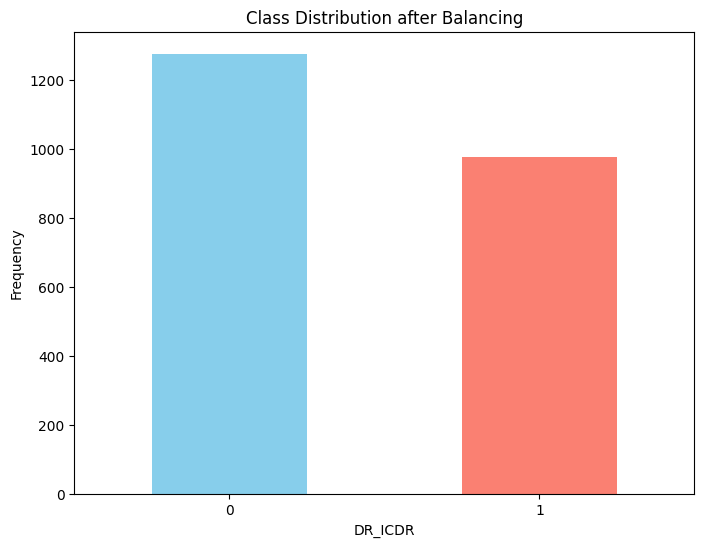

DR_ICDR
0    1275
1     975
Name: count, dtype: int64


In [22]:
SEED = 42

# Step 1: Separate the data based on the value of DR_ICDR
df_class_0 = df_filtered[df_filtered['DR_ICDR'] == 0]
df_class_1 = df_filtered[df_filtered['DR_ICDR'] == 1]

# Step 2: Downsample df_class_0 to 1025 values and keep all 975 values from df_class_1
df_class_0_downsampled = df_class_0.sample(n=1275, random_state=SEED)

# Combine the downsampled df_class_0 with df_class_1
df_balanced = pd.concat([df_class_0_downsampled, df_class_1])

# Shuffle the combined dataset
df_filtered = df_balanced.sample(frac=1, random_state=SEED).reset_index(drop=True)

# Visualize the class distribution
plt.figure(figsize=(8, 6))
df_filtered['DR_ICDR'].value_counts().plot(kind='bar', color=['skyblue', 'salmon'])
plt.title('Class Distribution after Balancing')
plt.xlabel('DR_ICDR')
plt.ylabel('Frequency')
plt.xticks(rotation=0)
plt.show()

# Print the final class distribution
print(df_filtered['DR_ICDR'].value_counts())


In [23]:
df_filtered['eye_normality_encoded'].value_counts()

eye_normality_encoded
0    1533
1     717
Name: count, dtype: int64

### extracting only the particular image for preprocessing 

In [23]:
import os
import shutil

# Assuming df_filtered is already loaded with your filtered data
image_ids = df_filtered['image_id'].tolist()  # Extract the list of image IDs

# Define the source directory where all images are located
source_dir = 'fundus_photos' 

# Define the destination directory where you want to save the filtered images
destination_dir = 'ne_image' 

# Create the destination directory if it doesn't exist
os.makedirs(destination_dir, exist_ok=True)

# Loop through the image IDs and copy the corresponding images to the new directory
for image_id in image_ids:
    # Construct the file name with the correct extension
    image_name = f'{image_id}.jpg'  # Adjust the extension if necessary
    source_path = os.path.join(source_dir, image_name)
    destination_path = os.path.join(destination_dir, image_name)
    
    # Check if the image file exists in the source directory
    if os.path.exists(source_path):
        shutil.copy(source_path, destination_path)
        print(f'Copied: {image_name}')
    else:
        print(f'Image not found: {image_name}')

print('Finished copying images.')


Copied: img02550.jpg
Image not found: img12606.jpg
Copied: img05357.jpg
Copied: img15214.jpg
Copied: img05466.jpg
Copied: img05900.jpg
Copied: img10217.jpg
Copied: img02389.jpg
Copied: img06356.jpg
Copied: img02306.jpg
Copied: img00020.jpg
Copied: img02712.jpg
Copied: img03354.jpg
Copied: img11513.jpg
Image not found: img12631.jpg
Copied: img04067.jpg
Copied: img07886.jpg
Copied: img13723.jpg
Image not found: img00791.jpg
Copied: img03691.jpg
Copied: img04742.jpg
Copied: img00036.jpg
Copied: img00074.jpg
Copied: img00129.jpg
Copied: img11680.jpg
Copied: img10206.jpg
Copied: img13456.jpg
Copied: img11133.jpg
Copied: img11092.jpg
Image not found: img16165.jpg
Copied: img00420.jpg
Image not found: img06678.jpg
Copied: img04679.jpg
Image not found: img09313.jpg
Image not found: img10642.jpg
Copied: img06811.jpg
Copied: img13054.jpg
Copied: img07115.jpg
Copied: img04513.jpg
Copied: img05650.jpg
Image not found: img05094.jpg
Copied: img10788.jpg
Image not found: img07345.jpg
Copied: img03804

In [24]:
# Check for NaN values in the eye_normality_encoded column
nan_count = df_filtered['eye_normality_encoded'].isna().sum()
print(f"Number of NaN values in eye_normality_encoded: {nan_count}")


Number of NaN values in eye_normality_encoded: 0


In [25]:
# Check the number of unique image IDs and labels
print(f"Number of unique image IDs: {df_filtered['image_id'].nunique()}")
print(f"Number of labels: {df_filtered['eye_normality_encoded'].nunique()}")

# Check for any remaining NaN values in the eye_normality_encoded column
print(f"Number of NaN values in eye_normality_encoded: {df_filtered['eye_normality_encoded'].isna().sum()}")


Number of unique image IDs: 2250
Number of labels: 2
Number of NaN values in eye_normality_encoded: 0


In [24]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import classification_report, roc_curve, auc, precision_recall_curve, confusion_matrix
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

def generate_classification_report_roc_pr(model, validation_generator):
    y_true = []
    y_pred = []

    for i in range(len(validation_generator)):
        X, y = validation_generator[i]
        y_true.extend(np.argmax(y, axis=1))
        y_pred_batch = model.predict(X)

        # Ensure y_pred_batch has the correct shape
        if len(y_pred_batch.shape) == 1:
            # Convert single output to two-class probabilities
            y_pred_batch = np.vstack([1 - y_pred_batch, y_pred_batch]).T

        y_pred.extend(y_pred_batch)

    y_pred = np.array(y_pred)

    # Debugging output to verify shapes
    print(f"y_pred shape: {y_pred.shape}")
    print(f"First few y_pred values:\n{y_pred[:5]}")

    y_pred_classes = np.argmax(y_pred, axis=1)
    print(f"y_true: {y_true[:5]}")
    print(f"y_pred_classes: {y_pred_classes[:5]}")

    print(classification_report(y_true, y_pred_classes))

    conf_matrix = confusion_matrix(y_true,y_pred_classes)
    plt.figure(figsize=(6,6))
    sns.heatmap(conf_matrix, annot=True, fmt='d', cmap= 'Blues', xticklabels=['class 0', 'class 1'], yticklabels=['class 0', 'class 1'])
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.title('Confusion Matrix')
    plt.show()

    # Generate ROC curve for both classes
    y_true_binarized = label_binarize(y_true, classes=[0, 1])

    # Correcting y_true_binarized shape if necessary
    if y_true_binarized.shape[1] == 1:
        y_true_binarized = np.hstack([1 - y_true_binarized, y_true_binarized])

    # Debugging output to verify y_true_binarized shape
    print(f"y_true_binarized shape: {y_true_binarized.shape}")

    fpr = dict()
    tpr = dict()
    roc_auc = dict()

    for i in range(2):  # Binary classification: classes 0 and 1
        fpr[i], tpr[i], _ = roc_curve(y_true_binarized[:, i], y_pred[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    plt.figure(figsize=(10, 8))
    for i in range(2):  # Only for classes 0 and 1
        plt.plot(fpr[i], tpr[i], lw=2, label=f'Class {i} (AUC = {roc_auc[i]:0.2f})')
    plt.plot([0, 1], [0, 1], 'k--', lw=2)
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic (ROC) Curve')
    plt.legend(loc="lower right")
    plt.show()

    # Generate Precision-Recall curve
    precision = dict()
    recall = dict()
    for i in range(2):  # Only for classes 0 and 1
        precision[i], recall[i], _ = precision_recall_curve(y_true_binarized[:, i], y_pred[:, i])

    plt.figure(figsize=(10, 8))
    for i in range(2):  # Only for classes 0 and 1
        plt.plot(recall[i], precision[i], lw=2, label=f'Class {i}')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend(loc="lower left")
    plt.show()


Training fold 1...


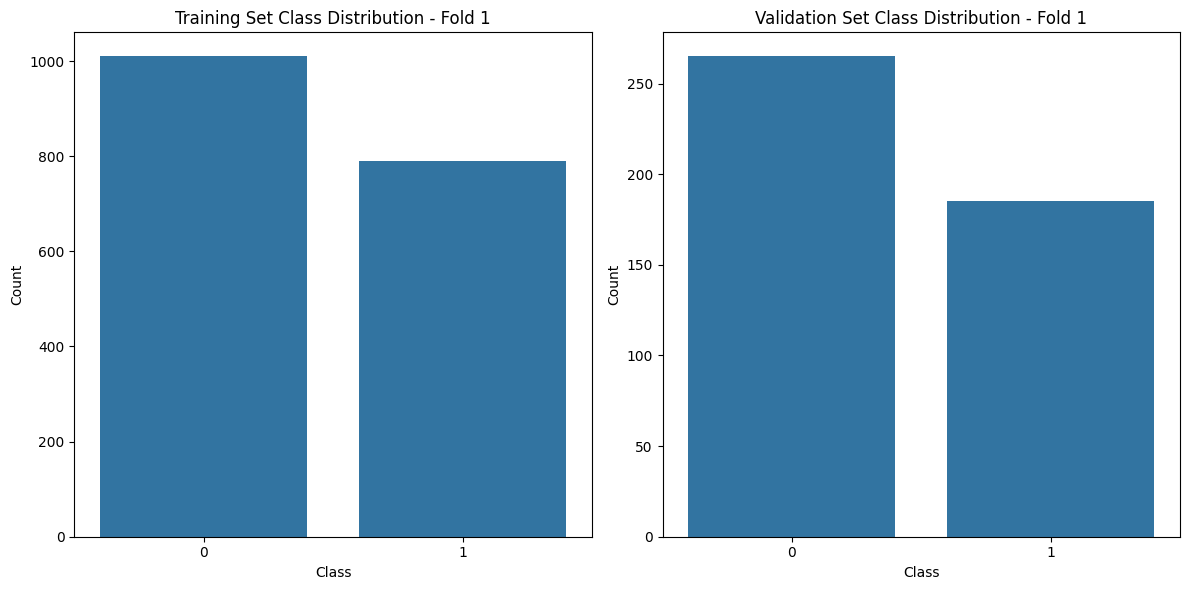

Epoch 1/5


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


56/56 ━━━━━━━━━━━━━━━━━━━━ 87s 1s/step - accuracy: 0.6112 - loss: 1.3122 - val_accuracy: 0.7143 - val_loss: 0.5310
Epoch 2/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 389s 7s/step - accuracy: 0.7373 - loss: 0.5076 - val_accuracy: 0.6094 - val_loss: 0.7163
Epoch 3/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 78s 1s/step - accuracy: 0.7631 - loss: 0.5114 - val_accuracy: 0.7143 - val_loss: 0.5693
Epoch 4/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 85s 1s/step - accuracy: 0.7857 - loss: 0.4319 - val_accuracy: 0.7790 - val_loss: 0.4600
Epoch 5/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 89s 2s/step - accuracy: 0.8202 - loss: 0.4026 - val_accuracy: 0.7656 - val_loss: 0.4752
14/14 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step - accuracy: 0.7524 - loss: 0.4923
Validation Accuracy for fold 1: 0.7656
Classification Report for fold 2
Training fold 2...


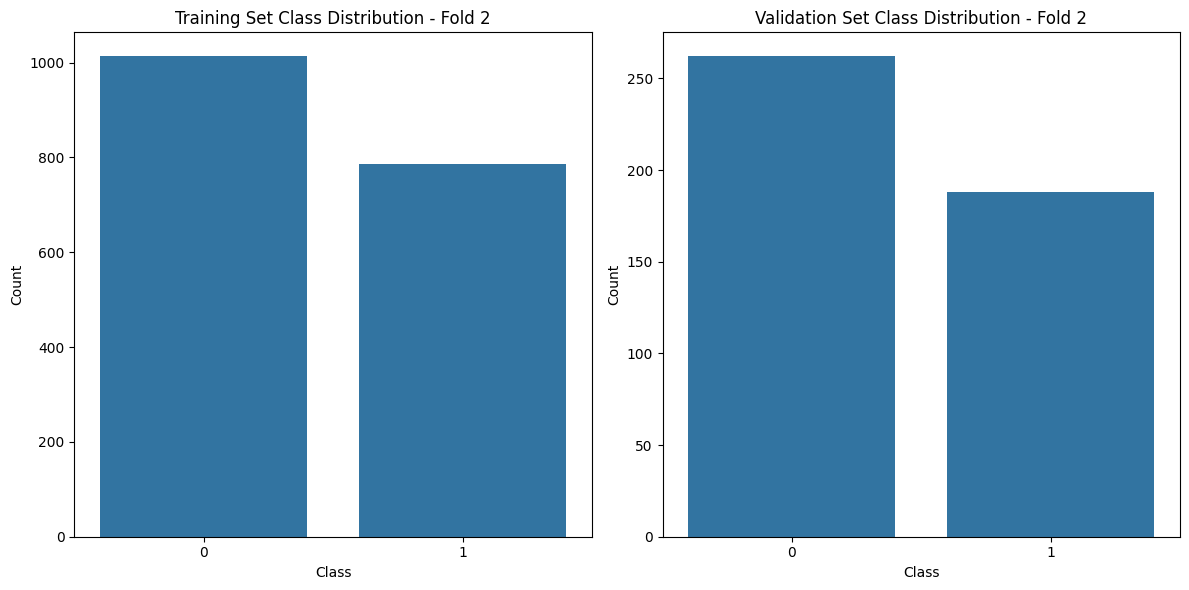

Epoch 1/5


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


56/56 ━━━━━━━━━━━━━━━━━━━━ 566s 10s/step - accuracy: 0.6608 - loss: 0.8280 - val_accuracy: 0.6786 - val_loss: 0.7073
Epoch 2/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 79s 1s/step - accuracy: 0.7443 - loss: 0.5381 - val_accuracy: 0.6830 - val_loss: 0.7397
Epoch 3/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 86s 1s/step - accuracy: 0.7611 - loss: 0.4908 - val_accuracy: 0.7969 - val_loss: 0.4687
Epoch 4/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 88s 1s/step - accuracy: 0.8146 - loss: 0.3943 - val_accuracy: 0.7567 - val_loss: 0.4846
Epoch 5/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 89s 2s/step - accuracy: 0.7998 - loss: 0.4371 - val_accuracy: 0.8013 - val_loss: 0.4372
14/14 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step - accuracy: 0.8005 - loss: 0.4421
Validation Accuracy for fold 2: 0.8013
Classification Report for fold 3
Training fold 3...


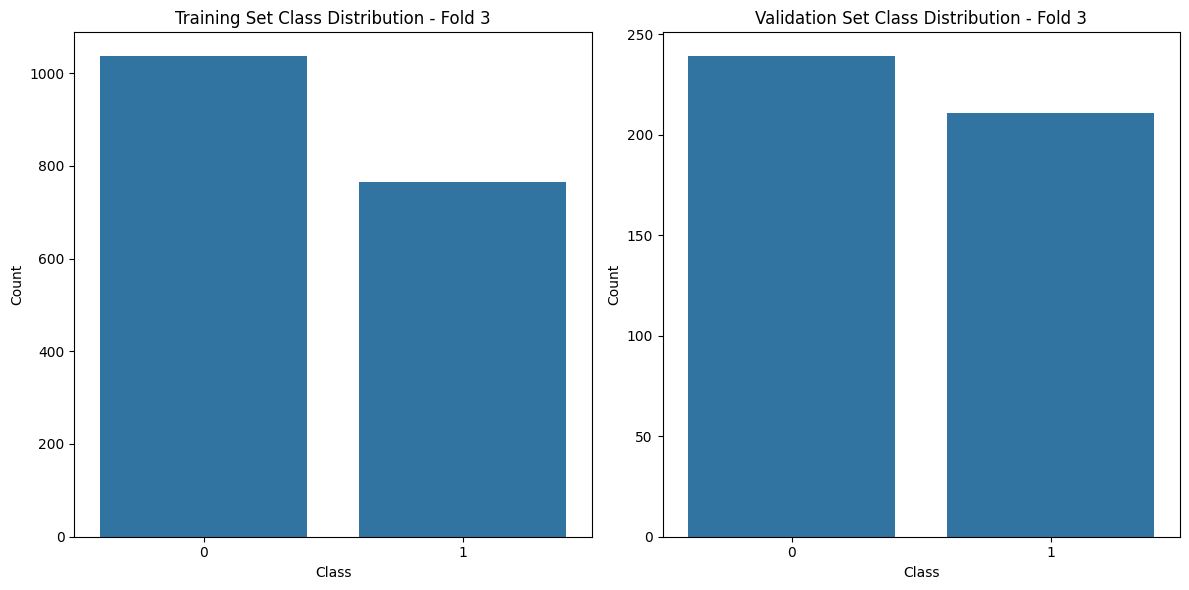

Epoch 1/5


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


56/56 ━━━━━━━━━━━━━━━━━━━━ 96s 2s/step - accuracy: 0.5939 - loss: 1.4920 - val_accuracy: 0.7321 - val_loss: 0.5136
Epoch 2/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 90s 2s/step - accuracy: 0.7457 - loss: 0.5147 - val_accuracy: 0.7723 - val_loss: 0.4500
Epoch 3/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 91s 2s/step - accuracy: 0.7865 - loss: 0.4630 - val_accuracy: 0.7812 - val_loss: 0.4261
Epoch 4/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 91s 2s/step - accuracy: 0.8072 - loss: 0.4280 - val_accuracy: 0.7924 - val_loss: 0.4217
Epoch 5/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 92s 2s/step - accuracy: 0.8087 - loss: 0.4211 - val_accuracy: 0.7388 - val_loss: 0.5576
14/14 ━━━━━━━━━━━━━━━━━━━━ 20s 1s/step - accuracy: 0.7296 - loss: 0.5755
Validation Accuracy for fold 3: 0.7366
Classification Report for fold 4
Training fold 4...


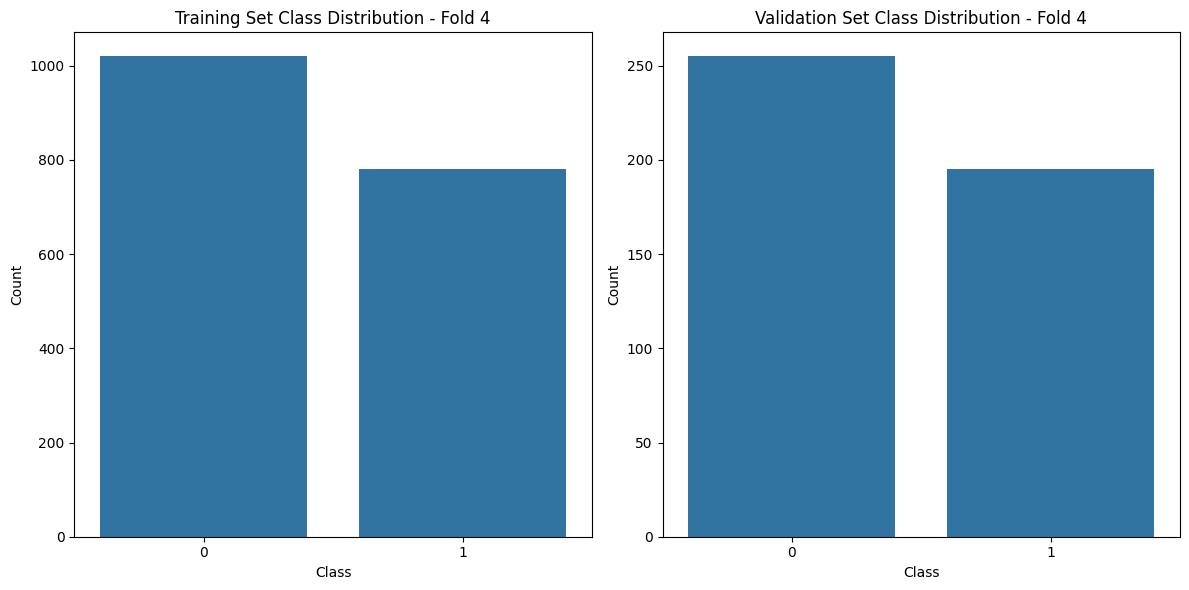

Epoch 1/5


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


56/56 ━━━━━━━━━━━━━━━━━━━━ 102s 2s/step - accuracy: 0.6544 - loss: 0.8095 - val_accuracy: 0.6719 - val_loss: 0.6236
Epoch 2/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 93s 2s/step - accuracy: 0.7493 - loss: 0.5139 - val_accuracy: 0.7991 - val_loss: 0.4408
Epoch 3/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 1144s 21s/step - accuracy: 0.7873 - loss: 0.4667 - val_accuracy: 0.7902 - val_loss: 0.4396
Epoch 4/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 1033s 19s/step - accuracy: 0.8210 - loss: 0.4025 - val_accuracy: 0.8147 - val_loss: 0.4118
Epoch 5/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 2025s 37s/step - accuracy: 0.8032 - loss: 0.4016 - val_accuracy: 0.8080 - val_loss: 0.4148
14/14 ━━━━━━━━━━━━━━━━━━━━ 14s 965ms/step - accuracy: 0.8120 - loss: 0.4357
Validation Accuracy for fold 4: 0.8080
Classification Report for fold 5
Training fold 5...


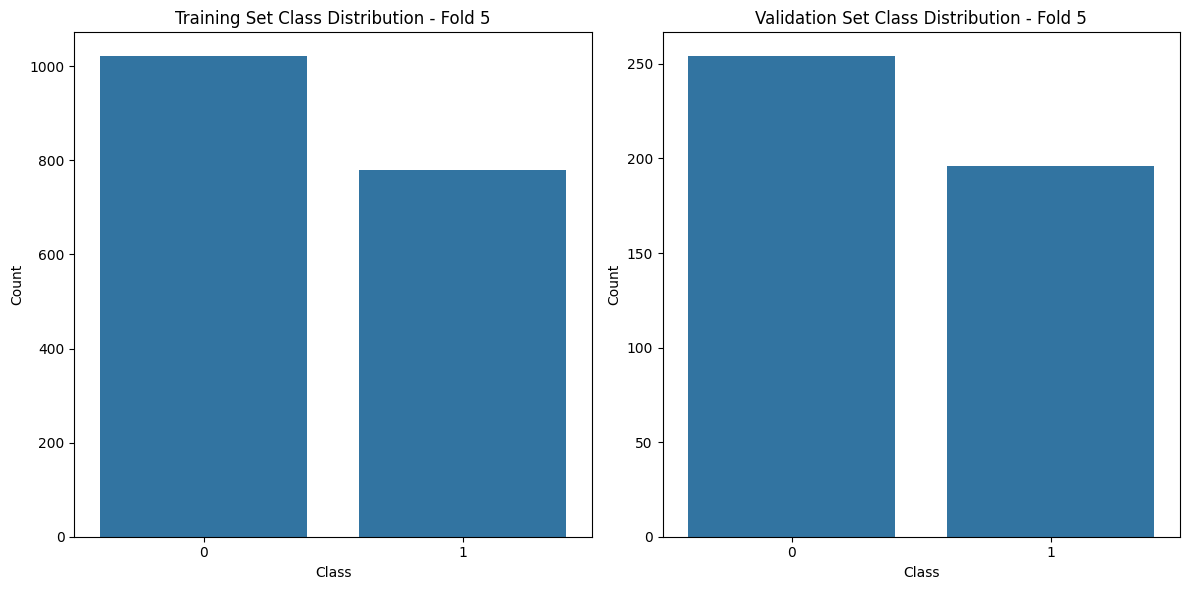

Epoch 1/5


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


56/56 ━━━━━━━━━━━━━━━━━━━━ 1922s 35s/step - accuracy: 0.5682 - loss: 1.4409 - val_accuracy: 0.7812 - val_loss: 0.4588
Epoch 2/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 925s 17s/step - accuracy: 0.7595 - loss: 0.4902 - val_accuracy: 0.7411 - val_loss: 0.4947
Epoch 3/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 1899s 34s/step - accuracy: 0.7737 - loss: 0.4703 - val_accuracy: 0.8326 - val_loss: 0.4056
Epoch 4/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 483s 9s/step - accuracy: 0.7725 - loss: 0.4516 - val_accuracy: 0.7946 - val_loss: 0.4540
Epoch 5/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 1012s 18s/step - accuracy: 0.7891 - loss: 0.4562 - val_accuracy: 0.7277 - val_loss: 0.5040
14/14 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step - accuracy: 0.7453 - loss: 0.4676
Validation Accuracy for fold 5: 0.7299
Classification Report for fold 6


In [34]:
import ssl
import certifi
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import pandas as pd
import numpy as np
import os
import seaborn as sns
import matplotlib.pyplot as plt
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import Sequence
from sklearn.model_selection import KFold
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc

# Use certifi's certificates for SSL verification
ssl._create_default_https_context = ssl.create_default_context(cafile=certifi.where())

# Configuration
IMAGE_SIZE_DENSENET = (224, 224)   # Densenet uses
BATCH_SIZE = 32
NUM_CLASSES = 2  # Binary classification
NUM_EPOCHS = 5
LEARNING_RATE = 0.001
KFOLDS = 5  # Number of folds for cross-validation
IMAGE_DIR = '/Users/chandraprakashsaravanan/Documents/Chandru_Dissertation/a-brazilian-multilabel-ophthalmological-dataset-brset-1.0.0/ne_image'  # Replace with the correct path to the new directory
DENSENET_WEIGHTS_PATH = '/Users/chandraprakashsaravanan/Documents/Chandru_Dissertation/a-brazilian-multilabel-ophthalmological-dataset-brset-1.0.0/scratch/densenet121_weights_tf_dim_ordering_tf_kernels_notop.h5'  # Replace with the correct path to your weights file

# Load the DataFrame
df_filtered = df_filtered

# Ensure filenames include extensions and are correct
df_filtered['image_id'] = df_filtered['image_id'].apply(lambda x: f"{x}.jpg" if not x.endswith(".jpg") else x)

class DataGenerator(Sequence):
    def __init__(self, dataframe, image_dir, batch_size, image_size, num_classes, shuffle=True):
        self.dataframe = dataframe
        self.image_dir = image_dir
        self.batch_size = batch_size
        self.image_size = image_size
        self.num_classes = num_classes
        self.shuffle = shuffle
        self.on_epoch_end()

    def __len__(self):
        return int(np.floor(len(self.dataframe) / self.batch_size))

    def __getitem__(self, index):
        indexes = self.indexes[index * self.batch_size:(index + 1) * self.batch_size]
        batch_df = self.dataframe.iloc[indexes]
        X, y = self.__data_generation(batch_df)
        return X, y

    def on_epoch_end(self):
        self.indexes = np.arange(len(self.dataframe))
        if self.shuffle:
            np.random.shuffle(self.indexes)

    def __data_generation(self, batch_df):
        X = np.empty((self.batch_size, *self.image_size, 3))
        y = np.empty((self.batch_size), dtype=int)
        for i, (_, row) in enumerate(batch_df.iterrows()):
            img_name = row['image_id']  # Adjust the extension if necessary
            img_path = os.path.join(self.image_dir, img_name)
            img = load_img(img_path, target_size=self.image_size)
            img = img_to_array(img) / 255.0  # Normalize the image
            X[i,] = img
            y[i] = row['DR_ICDR']

        return X, tf.keras.utils.to_categorical(y, num_classes=self.num_classes)

# Load DenseNet121 Model with Local Weights
def create_densenet_model():
    base_model_densenet = DenseNet121(weights=DENSENET_WEIGHTS_PATH, include_top=False, input_shape=(*IMAGE_SIZE_DENSENET, 3))
    x_densenet = base_model_densenet.output
    x_densenet = GlobalAveragePooling2D()(x_densenet)
    x_densenet = Dense(1024, activation='relu')(x_densenet)
    predictions_densenet = Dense(NUM_CLASSES, activation='softmax')(x_densenet)

    model_densenet = Model(inputs=base_model_densenet.input, outputs=predictions_densenet)

    # Freeze the base model layers for Inception V3
    for layer in base_model_densenet.layers:
        layer.trainable = False

    # Compile Inception V3 Model
    model_densenet.compile(optimizer=Adam(learning_rate=LEARNING_RATE), loss='categorical_crossentropy', metrics=['accuracy'])
    
    return model_densenet


kf = KFold(n_splits=KFOLDS, shuffle=True, random_state=42)
fold_no = 1

for train_index, val_index in kf.split(df_filtered):
    print(f"Training fold {fold_no}...")
    
    train_df = df_filtered.iloc[train_index]
    val_df = df_filtered.iloc[val_index]

    # Visualize the class distribution for training and validation data
    plt.figure(figsize=(12, 6))

    plt.subplot(1, 2, 1)
    sns.countplot(x='DR_ICDR', data=train_df)
    plt.title(f'Training Set Class Distribution - Fold {fold_no}')
    plt.xlabel('Class')
    plt.ylabel('Count')

    plt.subplot(1, 2, 2)
    sns.countplot(x='DR_ICDR', data=val_df)
    plt.title(f'Validation Set Class Distribution - Fold {fold_no}')
    plt.xlabel('Class')
    plt.ylabel('Count')

    plt.tight_layout()
    plt.show()
    
    train_generator_densenet = DataGenerator(train_df, IMAGE_DIR, BATCH_SIZE, IMAGE_SIZE_DENSENET, NUM_CLASSES)
    validation_generator_densenet = DataGenerator(val_df, IMAGE_DIR, BATCH_SIZE, IMAGE_SIZE_DENSENET, NUM_CLASSES)
    
    # Create a new instance of the model for each fold
    model_densenet = create_densenet_model()
    
    # Train the model
    history = model_densenet.fit(
        train_generator_densenet,
        epochs=NUM_EPOCHS,
        validation_data=validation_generator_densenet
    )
    
    # Evaluate the model
    val_loss, val_accuracy = model_densenet.evaluate(validation_generator_densenet)
    print(f"Validation Accuracy for fold {fold_no}: {val_accuracy:.4f}")

    print(f"Classification Report for fold {fold_no+1}")

    
    # Save the model
    model_densenet.save(f'densenet_model_fold_{fold_no}.keras')
    
    fold_no += 1


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 983ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 957ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 943ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 948ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 949ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 917ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 944ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 945ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 945ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 947ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 945ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 940ms/step
y_pred shape: (448, 2)
First few y_pred values:
[[0.58165216 0.41834772]
 [0.18247874 0.8175213 ]
 [0.81367385 0.18632615]
 [0.7011146  0.29888538]
 [0.09089352 0.90910643]]
y_true: [0, 1, 0, 0, 1]
y_pred_classes: [0 1 0 0 1]
              precision    recall  f1-score   support

           0       0.91      0.57      0.71       254
           1       0.62      0.93      0.75       194

    accuracy                           0.73       448
   macro avg    

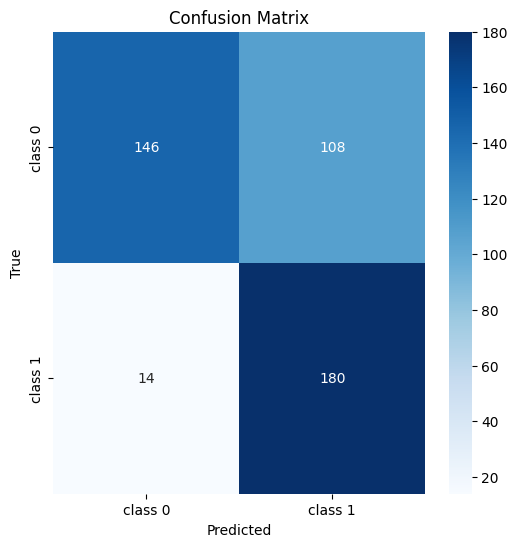

y_true_binarized shape: (448, 2)


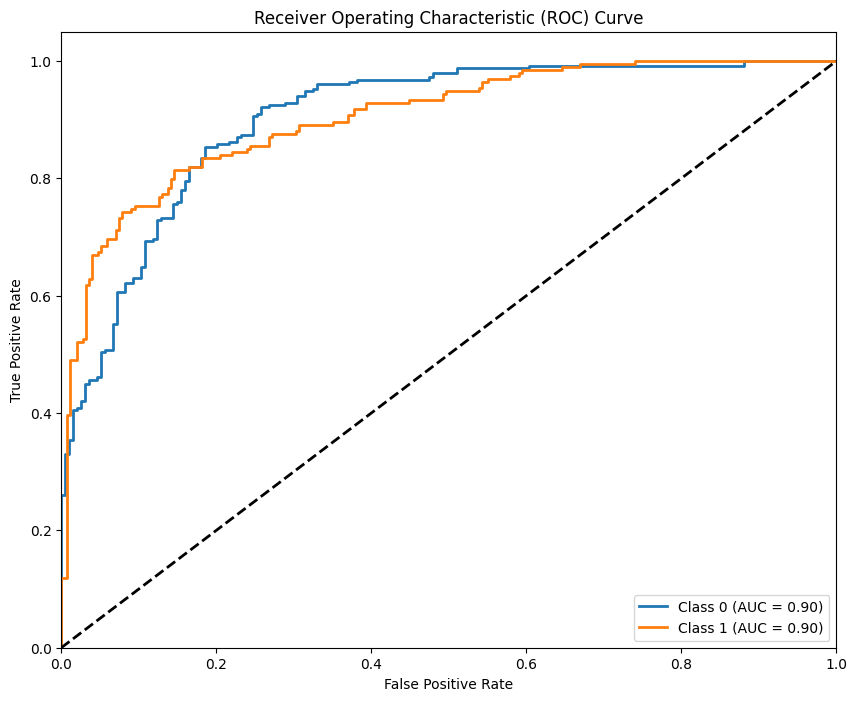

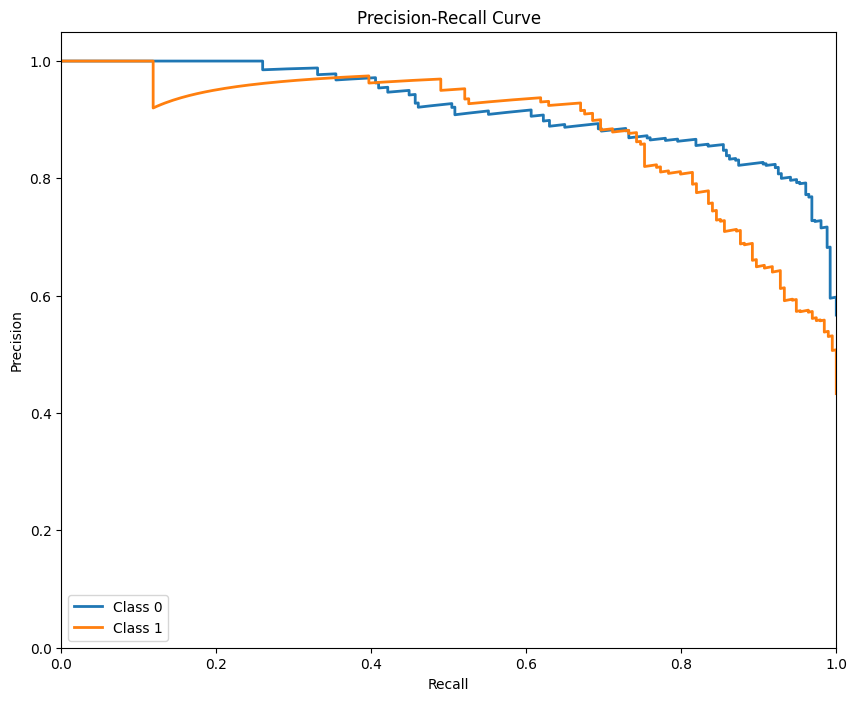

In [40]:
generate_classification_report_roc_pr(model_densenet, validation_generator_densenet)

Training fold 1...


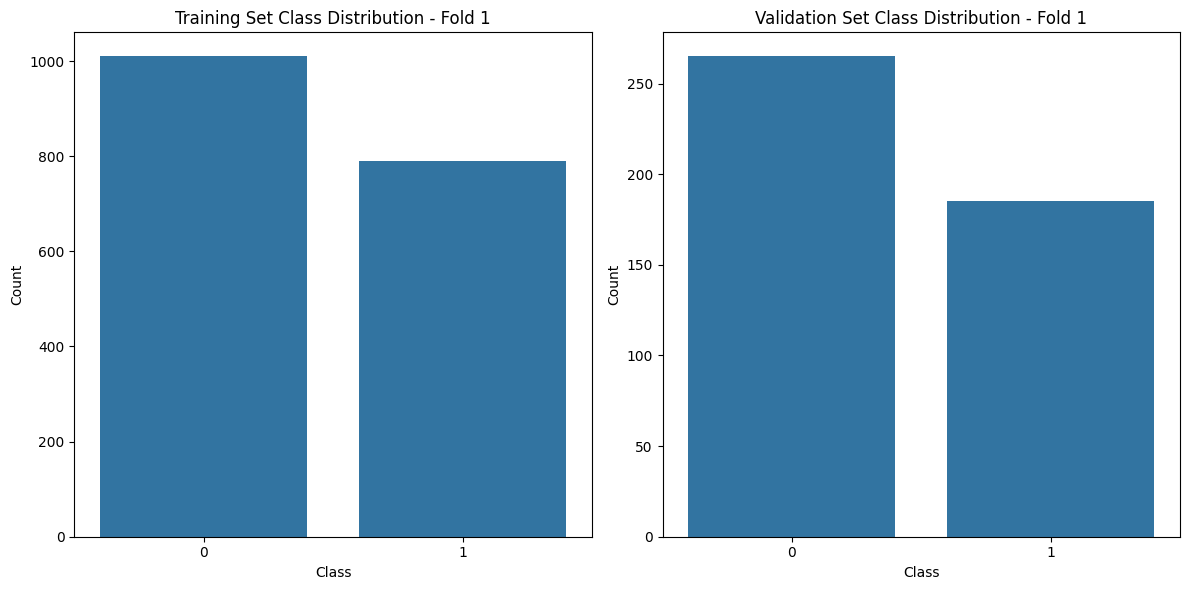

Epoch 1/5


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


56/56 ━━━━━━━━━━━━━━━━━━━━ 121s 2s/step - accuracy: 0.5942 - loss: 1.3138 - val_accuracy: 0.7031 - val_loss: 0.5525
Epoch 2/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 123s 2s/step - accuracy: 0.7589 - loss: 0.5056 - val_accuracy: 0.7768 - val_loss: 0.4723
Epoch 3/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 123s 2s/step - accuracy: 0.7919 - loss: 0.4574 - val_accuracy: 0.7902 - val_loss: 0.4497
Epoch 4/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 124s 2s/step - accuracy: 0.8129 - loss: 0.4371 - val_accuracy: 0.7812 - val_loss: 0.4495
Epoch 5/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 127s 2s/step - accuracy: 0.7833 - loss: 0.4638 - val_accuracy: 0.7210 - val_loss: 0.5299
14/14 ━━━━━━━━━━━━━━━━━━━━ 25s 2s/step - accuracy: 0.7366 - loss: 0.5187
Validation Accuracy for fold 1: 0.7210
Classification Report for fold 2
Training fold 2...


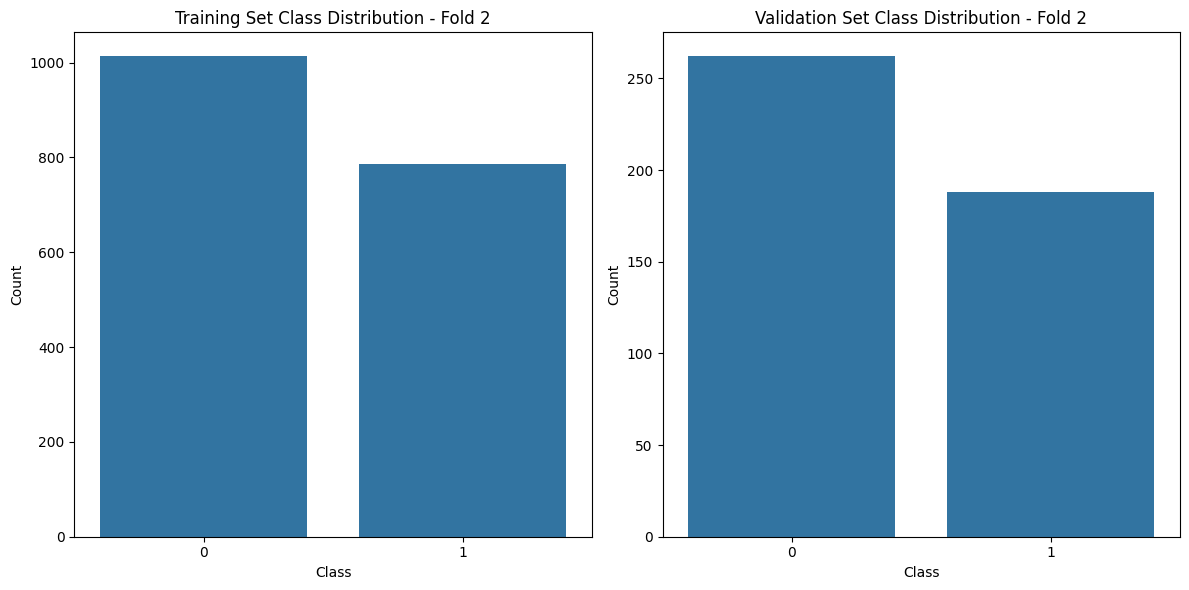

Epoch 1/5


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


56/56 ━━━━━━━━━━━━━━━━━━━━ 132s 2s/step - accuracy: 0.6371 - loss: 1.0559 - val_accuracy: 0.7478 - val_loss: 0.5210
Epoch 2/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 532s 5s/step - accuracy: 0.7763 - loss: 0.4751 - val_accuracy: 0.7812 - val_loss: 0.4973
Epoch 3/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 127s 2s/step - accuracy: 0.7946 - loss: 0.4554 - val_accuracy: 0.7433 - val_loss: 0.5126
Epoch 4/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 131s 2s/step - accuracy: 0.7650 - loss: 0.4868 - val_accuracy: 0.7567 - val_loss: 0.5119
Epoch 5/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 138s 2s/step - accuracy: 0.8043 - loss: 0.4080 - val_accuracy: 0.7812 - val_loss: 0.4950
14/14 ━━━━━━━━━━━━━━━━━━━━ 27s 2s/step - accuracy: 0.7566 - loss: 0.5243
Validation Accuracy for fold 2: 0.7812
Classification Report for fold 3
Training fold 3...


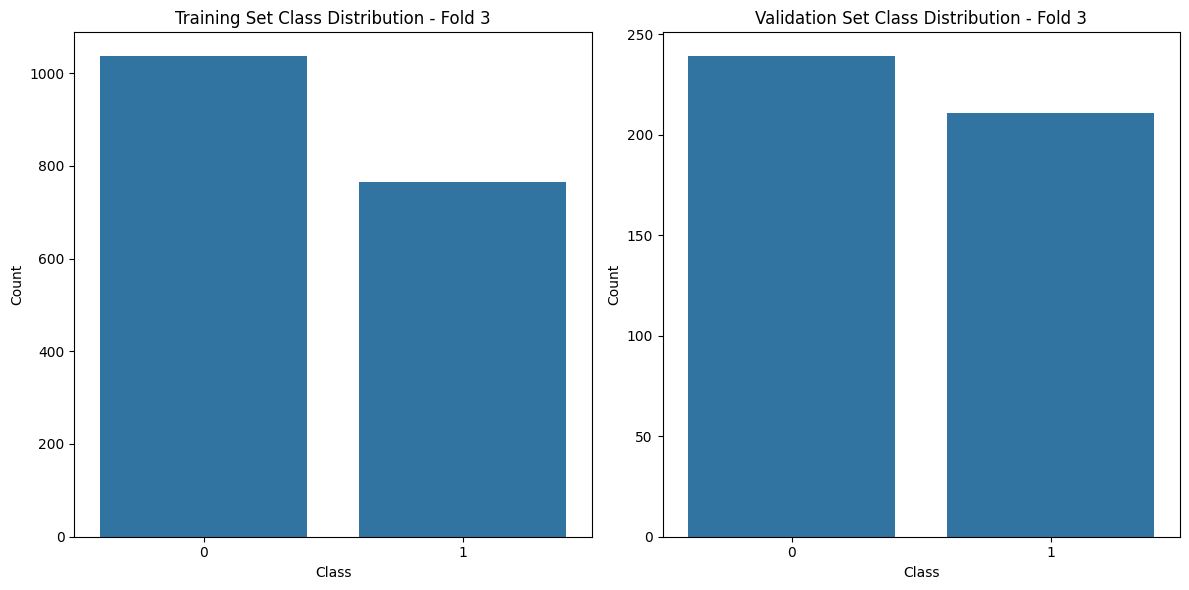

Epoch 1/5


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


56/56 ━━━━━━━━━━━━━━━━━━━━ 144s 2s/step - accuracy: 0.5924 - loss: 1.1561 - val_accuracy: 0.6830 - val_loss: 0.6081
Epoch 2/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 138s 2s/step - accuracy: 0.7466 - loss: 0.5141 - val_accuracy: 0.7701 - val_loss: 0.5023
Epoch 3/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 130s 2s/step - accuracy: 0.7819 - loss: 0.4753 - val_accuracy: 0.7500 - val_loss: 0.5303
Epoch 4/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 131s 2s/step - accuracy: 0.7919 - loss: 0.4377 - val_accuracy: 0.7768 - val_loss: 0.4809
Epoch 5/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 134s 2s/step - accuracy: 0.8163 - loss: 0.4083 - val_accuracy: 0.7790 - val_loss: 0.4534
14/14 ━━━━━━━━━━━━━━━━━━━━ 26s 2s/step - accuracy: 0.7593 - loss: 0.4811
Validation Accuracy for fold 3: 0.7768
Classification Report for fold 4
Training fold 4...


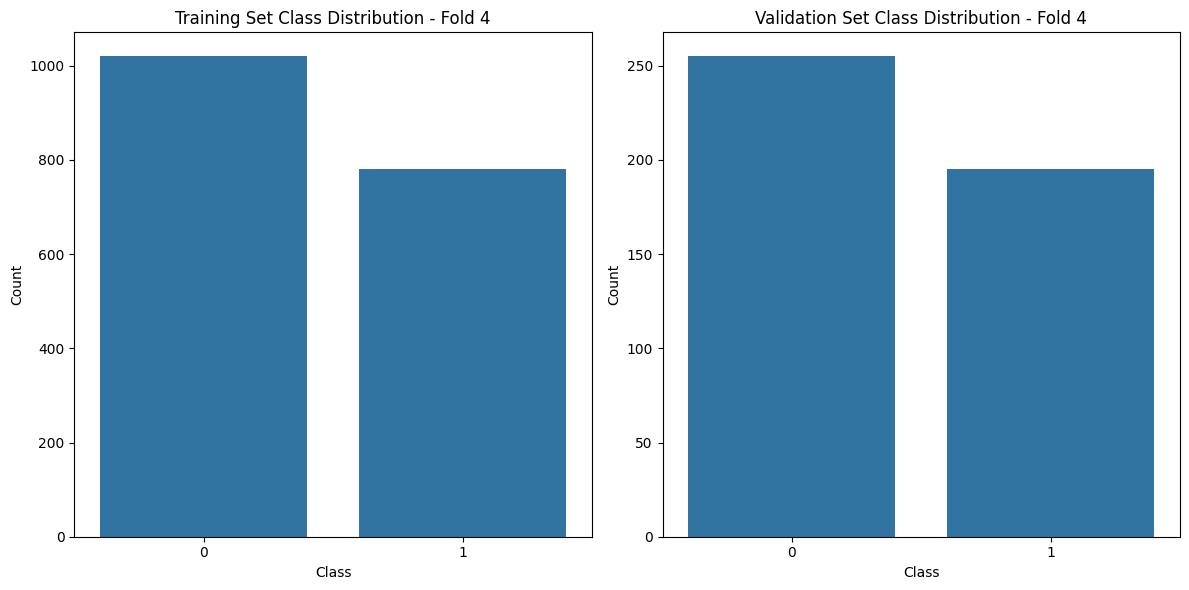

Epoch 1/5


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


56/56 ━━━━━━━━━━━━━━━━━━━━ 136s 2s/step - accuracy: 0.5905 - loss: 1.3466 - val_accuracy: 0.7299 - val_loss: 0.5115
Epoch 2/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 132s 2s/step - accuracy: 0.7602 - loss: 0.5006 - val_accuracy: 0.7455 - val_loss: 0.5544
Epoch 3/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 132s 2s/step - accuracy: 0.7730 - loss: 0.4772 - val_accuracy: 0.7879 - val_loss: 0.4510
Epoch 4/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 135s 2s/step - accuracy: 0.8048 - loss: 0.4418 - val_accuracy: 0.7812 - val_loss: 0.4393
Epoch 5/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 133s 2s/step - accuracy: 0.8179 - loss: 0.4093 - val_accuracy: 0.7946 - val_loss: 0.4257
14/14 ━━━━━━━━━━━━━━━━━━━━ 26s 2s/step - accuracy: 0.7941 - loss: 0.4147
Validation Accuracy for fold 4: 0.7924
Classification Report for fold 5
Training fold 5...


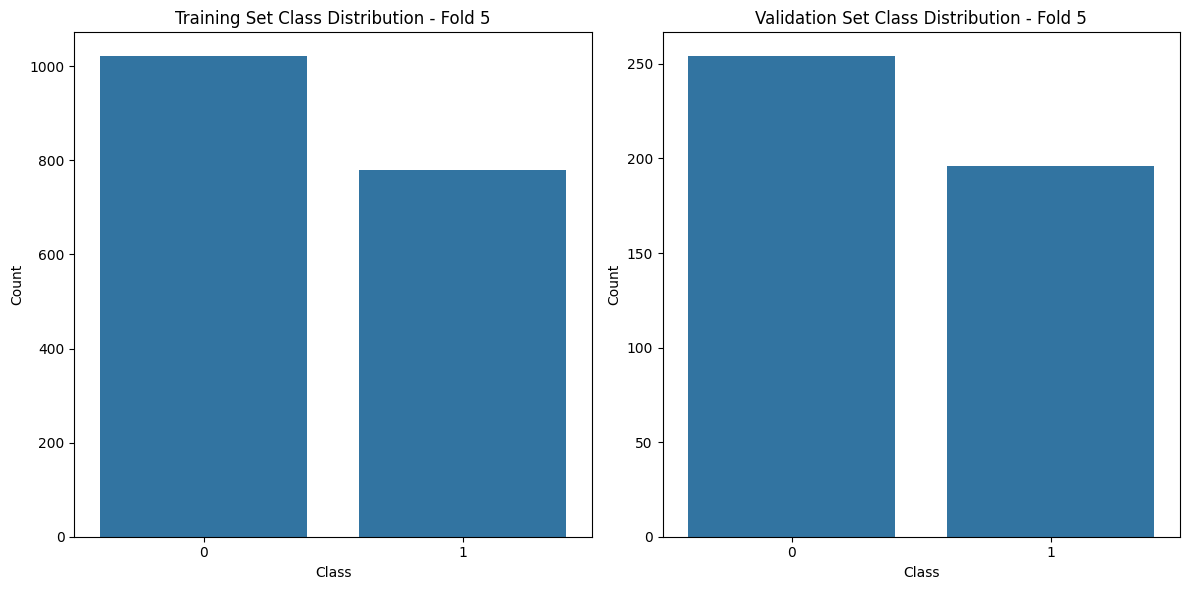

Epoch 1/5


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


56/56 ━━━━━━━━━━━━━━━━━━━━ 137s 2s/step - accuracy: 0.6142 - loss: 1.0550 - val_accuracy: 0.6696 - val_loss: 0.5927
Epoch 2/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 133s 2s/step - accuracy: 0.7226 - loss: 0.5219 - val_accuracy: 0.7857 - val_loss: 0.4743
Epoch 3/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 133s 2s/step - accuracy: 0.7837 - loss: 0.4603 - val_accuracy: 0.8214 - val_loss: 0.4607
Epoch 4/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 135s 2s/step - accuracy: 0.8027 - loss: 0.4252 - val_accuracy: 0.8080 - val_loss: 0.4578
Epoch 5/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 133s 2s/step - accuracy: 0.8141 - loss: 0.4125 - val_accuracy: 0.8281 - val_loss: 0.4498
14/14 ━━━━━━━━━━━━━━━━━━━━ 26s 2s/step - accuracy: 0.8202 - loss: 0.4462
Validation Accuracy for fold 5: 0.8237
Classification Report for fold 6


In [41]:
import ssl
import certifi
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import pandas as pd
import numpy as np
import os
import seaborn as sns
import matplotlib.pyplot as plt
from tensorflow.keras.applications import InceptionV3
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import Sequence
from sklearn.model_selection import KFold
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc

# Use certifi's certificates for SSL verification
ssl._create_default_https_context = ssl.create_default_context(cafile=certifi.where())

# Configuration
IMAGE_SIZE_INCEPTION = (299, 299)   # Inception V3 uses 299x299 input size
BATCH_SIZE = 32
NUM_CLASSES = 2  # Binary classification
NUM_EPOCHS = 5
LEARNING_RATE = 0.001
KFOLDS = 5  # Number of folds for cross-validation
IMAGE_DIR = '/Users/chandraprakashsaravanan/Documents/Chandru_Dissertation/a-brazilian-multilabel-ophthalmological-dataset-brset-1.0.0/ne_image'  # Replace with the correct path to the new directory
INCEPTION_WEIGHTS_PATH = '/Users/chandraprakashsaravanan/Documents/Chandru_Dissertation/a-brazilian-multilabel-ophthalmological-dataset-brset-1.0.0/scratch/inception_v3_weights_tf_dim_ordering_tf_kernels_notop.h5'  # Replace with the correct path to your weights file

# Load the DataFrame
df_filtered = df_filtered


# Ensure filenames include extensions and are correct
df_filtered['image_id'] = df_filtered['image_id'].apply(lambda x: f"{x}.jpg" if not x.endswith(".jpg") else x)

# Custom Data Generator
class DataGenerator(Sequence):
    def __init__(self, dataframe, image_dir, batch_size, image_size, num_classes, shuffle=True):
        self.dataframe = dataframe
        self.image_dir = image_dir
        self.batch_size = batch_size
        self.image_size = image_size
        self.num_classes = num_classes
        self.shuffle = shuffle
        self.on_epoch_end()

    def __len__(self):
        return int(np.floor(len(self.dataframe) / self.batch_size))

    def __getitem__(self, index):
        indexes = self.indexes[index * self.batch_size:(index + 1) * self.batch_size]
        batch_df = self.dataframe.iloc[indexes]
        X, y = self.__data_generation(batch_df)
        return X, y

    def on_epoch_end(self):
        self.indexes = np.arange(len(self.dataframe))
        if self.shuffle:
            np.random.shuffle(self.indexes)

    def __data_generation(self, batch_df):
        X = np.empty((self.batch_size, *self.image_size, 3))
        y = np.empty((self.batch_size), dtype=int)
        for i, (_, row) in enumerate(batch_df.iterrows()):
            img_name = row['image_id'] # Adjust the extension if necessary
            img_path = os.path.join(self.image_dir, img_name)
            img = load_img(img_path, target_size=self.image_size)
            img = img_to_array(img) / 255.0  # Normalize the image
            X[i,] = img
            y[i] = row['DR_ICDR']

        return X, tf.keras.utils.to_categorical(y, num_classes=self.num_classes)

# Load Inception V3 Model with Local Weights
def create_inception_model():
    base_model_inception = InceptionV3(weights=INCEPTION_WEIGHTS_PATH, include_top=False, input_shape=(*IMAGE_SIZE_INCEPTION, 3))
    x_inception = base_model_inception.output
    x_inception = GlobalAveragePooling2D()(x_inception)
    x_inception = Dense(1024, activation='relu')(x_inception)
    predictions_inception = Dense(NUM_CLASSES, activation='softmax')(x_inception)

    model_inception = Model(inputs=base_model_inception.input, outputs=predictions_inception)

    # Freeze the base model layers for Inception V3
    for layer in base_model_inception.layers:
        layer.trainable = False

    # Compile Inception V3 Model
    model_inception.compile(optimizer=Adam(learning_rate=LEARNING_RATE), loss='categorical_crossentropy', metrics=['accuracy'])
    
    return model_inception


kf = KFold(n_splits=KFOLDS, shuffle=True, random_state=42)
fold_no = 1

for train_index, val_index in kf.split(df_filtered):
    print(f"Training fold {fold_no}...")
    
    train_df = df_filtered.iloc[train_index]
    val_df = df_filtered.iloc[val_index]

    # Visualize the class distribution for training and validation data
    plt.figure(figsize=(12, 6))

    plt.subplot(1, 2, 1)
    sns.countplot(x='DR_ICDR', data=train_df)
    plt.title(f'Training Set Class Distribution - Fold {fold_no}')
    plt.xlabel('Class')
    plt.ylabel('Count')

    plt.subplot(1, 2, 2)
    sns.countplot(x='DR_ICDR', data=val_df)
    plt.title(f'Validation Set Class Distribution - Fold {fold_no}')
    plt.xlabel('Class')
    plt.ylabel('Count')

    plt.tight_layout()
    plt.show()
    
    train_generator_inception = DataGenerator(train_df, IMAGE_DIR, BATCH_SIZE, IMAGE_SIZE_INCEPTION, NUM_CLASSES)
    validation_generator_inception = DataGenerator(val_df, IMAGE_DIR, BATCH_SIZE, IMAGE_SIZE_INCEPTION, NUM_CLASSES)
    
    # Create a new instance of the model for each fold
    model_inception = create_inception_model()
    
    # Train the model
    history = model_inception.fit(
        train_generator_inception,
        epochs=NUM_EPOCHS,
        validation_data=validation_generator_inception
    )
    
    # Evaluate the model
    val_loss, val_accuracy = model_inception.evaluate(validation_generator_inception)
    print(f"Validation Accuracy for fold {fold_no}: {val_accuracy:.4f}")

    print(f"Classification Report for fold {fold_no+1}")
    
    # Save the model
    model_inception.save(f'inception_v3_model_fold_{fold_no}.keras')
    
    fold_no += 1


1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
y_pred shape: (448, 2)
First few y_pred values:
[[0.13390563 0.86609435]
 [0.07105966 0.9289403 ]
 [0.924113   0.07588695]
 [0.6837478  0.31625214]
 [0.92423743 0.0757626 ]]
y_true: [1, 1, 0, 0, 0]
y_pred_classes: [1 1 0 0 0]
              precision    recall  f1-score   support

           0       0.79      0.94      0.86       253
           1       0.89      0.68      0.77       195

    accuracy                           0.82       448
   macro avg       0.84      0.81      0.81       44

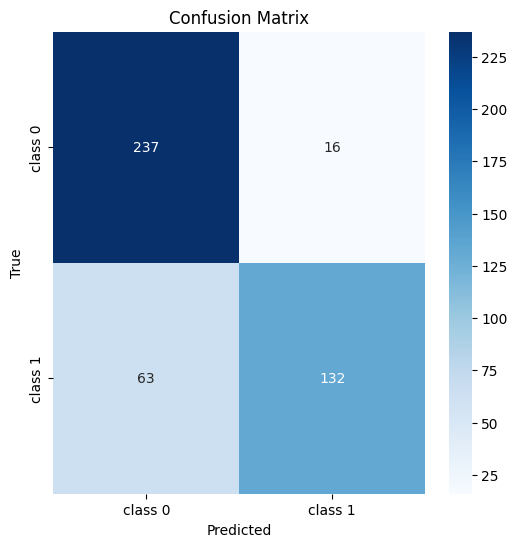

y_true_binarized shape: (448, 2)


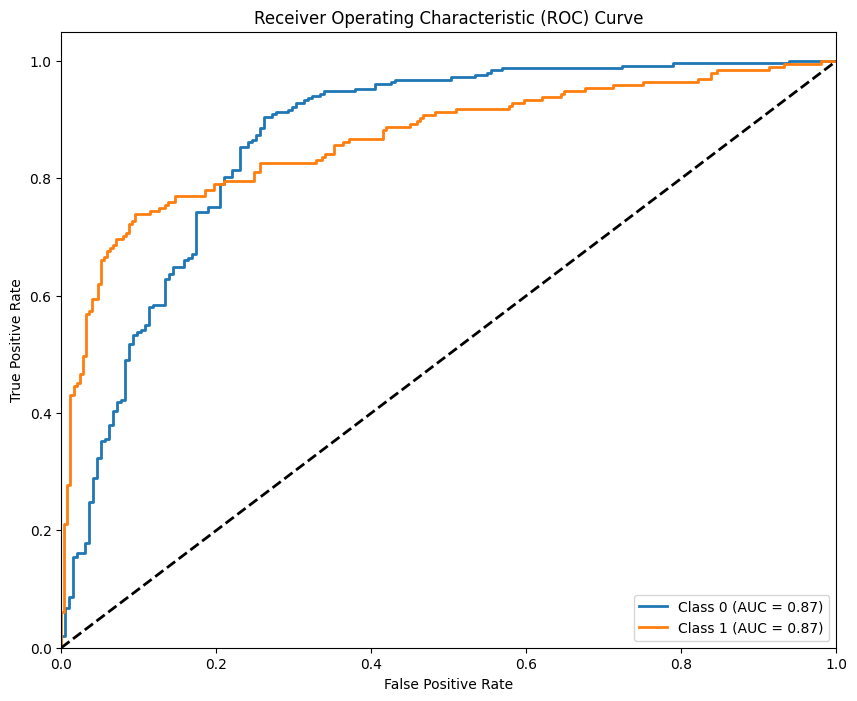

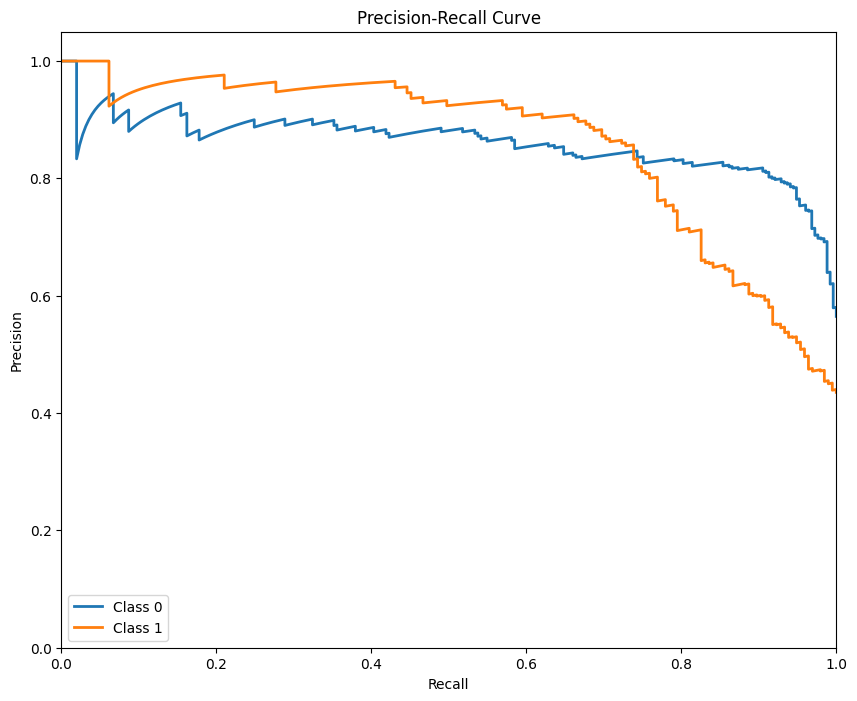

In [42]:
generate_classification_report_roc_pr(model_inception, validation_generator_inception)

Training fold 1...


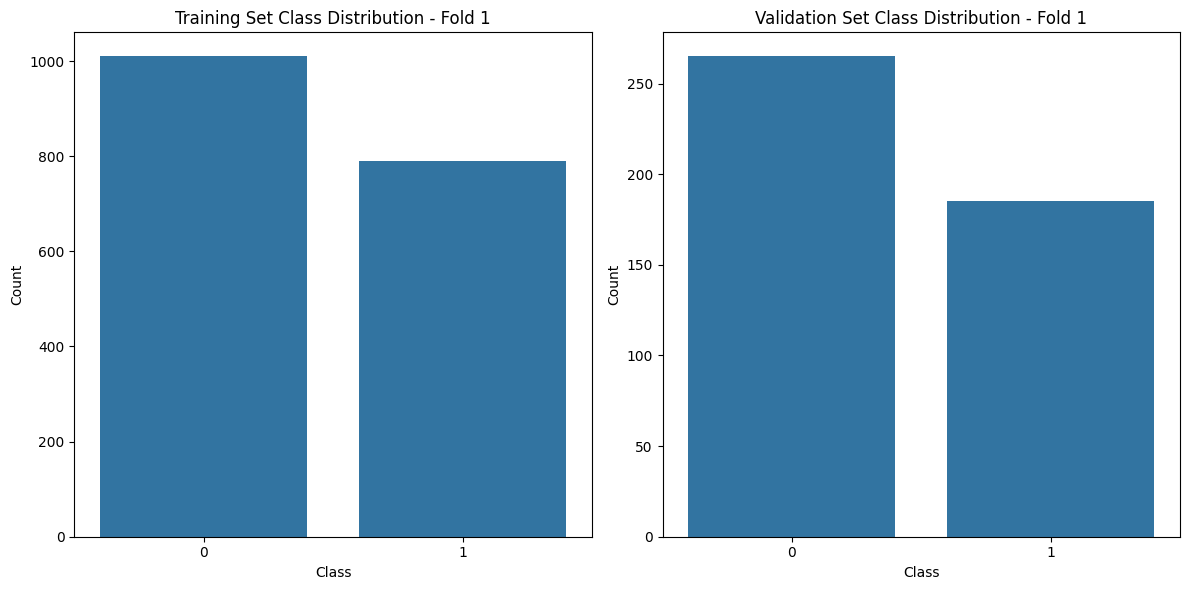

Epoch 1/5


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


56/56 ━━━━━━━━━━━━━━━━━━━━ 100s 2s/step - accuracy: 0.4934 - loss: 0.8142 - val_accuracy: 0.5871 - val_loss: 0.6789
Epoch 2/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 89s 2s/step - accuracy: 0.5635 - loss: 0.6855 - val_accuracy: 0.5893 - val_loss: 0.6790
Epoch 3/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 89s 2s/step - accuracy: 0.5612 - loss: 0.6863 - val_accuracy: 0.5893 - val_loss: 0.6784
Epoch 4/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 92s 2s/step - accuracy: 0.5516 - loss: 0.6887 - val_accuracy: 0.5871 - val_loss: 0.6795
Epoch 5/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 89s 1s/step - accuracy: 0.5618 - loss: 0.6863 - val_accuracy: 0.5871 - val_loss: 0.6799
14/14 ━━━━━━━━━━━━━━━━━━━━ 11s 771ms/step - accuracy: 0.5535 - loss: 0.6874
Validation Accuracy for fold 1: 0.5893
Classification Report for fold 2
Training fold 2...


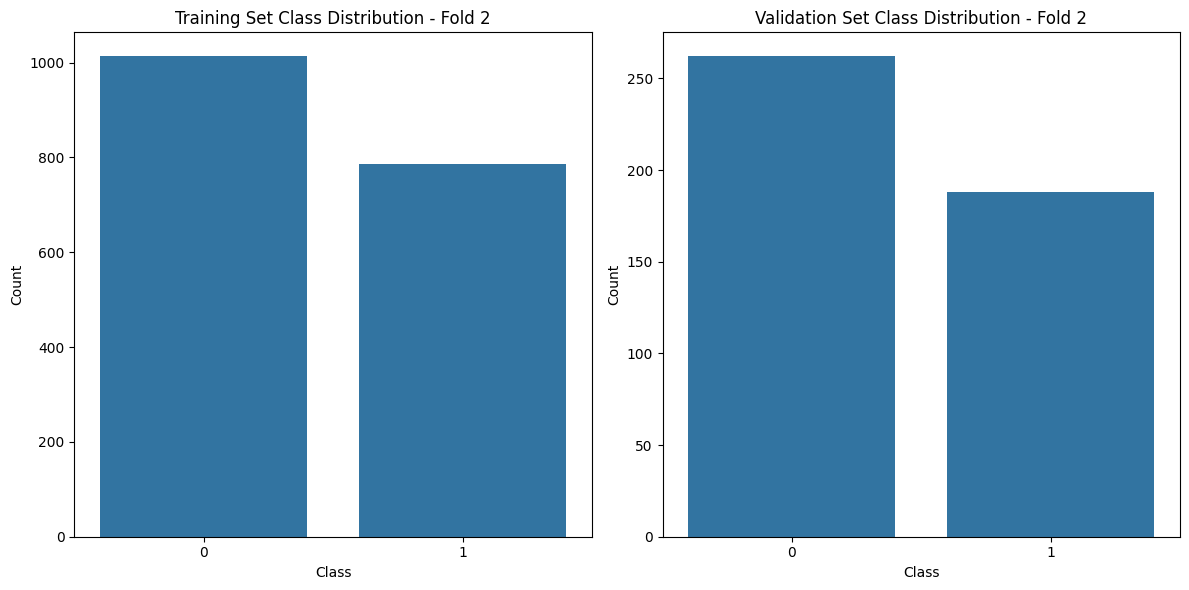

Epoch 1/5


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


56/56 ━━━━━━━━━━━━━━━━━━━━ 92s 2s/step - accuracy: 0.5510 - loss: 0.7942 - val_accuracy: 0.5826 - val_loss: 0.6885
Epoch 2/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 89s 2s/step - accuracy: 0.5612 - loss: 0.6873 - val_accuracy: 0.5826 - val_loss: 0.6795
Epoch 3/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 92s 2s/step - accuracy: 0.5647 - loss: 0.6846 - val_accuracy: 0.5804 - val_loss: 0.6802
Epoch 4/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 92s 2s/step - accuracy: 0.5608 - loss: 0.6873 - val_accuracy: 0.5804 - val_loss: 0.6802
Epoch 5/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 90s 2s/step - accuracy: 0.5713 - loss: 0.6835 - val_accuracy: 0.5848 - val_loss: 0.6794
14/14 ━━━━━━━━━━━━━━━━━━━━ 11s 755ms/step - accuracy: 0.5661 - loss: 0.6844
Validation Accuracy for fold 2: 0.5804
Classification Report for fold 3
Training fold 3...


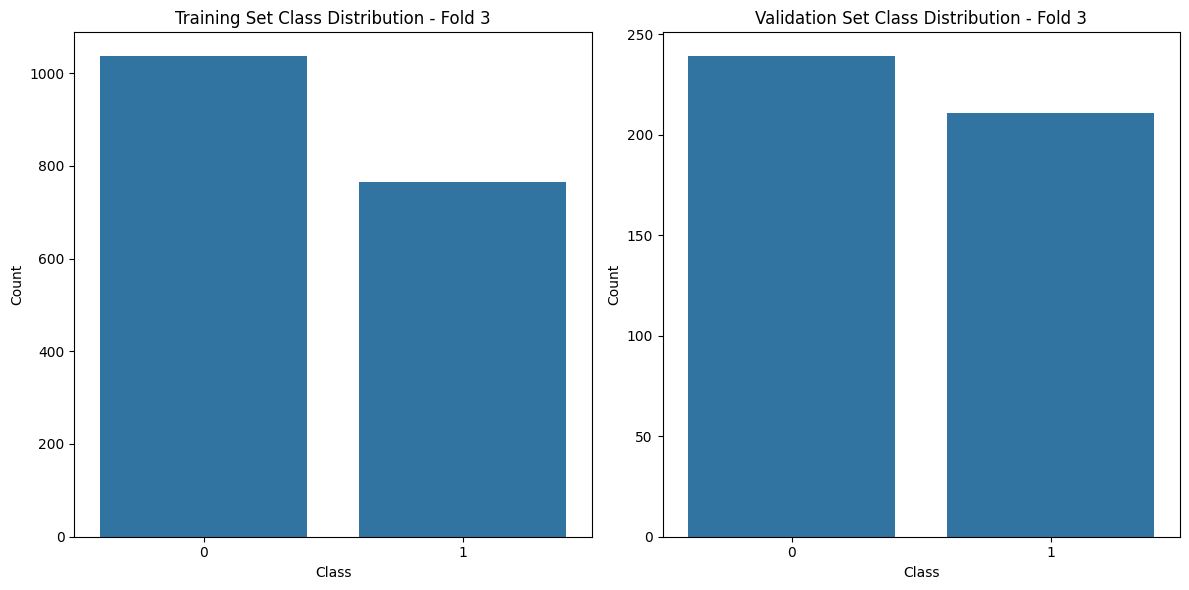

Epoch 1/5


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


56/56 ━━━━━━━━━━━━━━━━━━━━ 94s 2s/step - accuracy: 0.5334 - loss: 1.2380 - val_accuracy: 0.5335 - val_loss: 0.6916
Epoch 2/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 93s 2s/step - accuracy: 0.5638 - loss: 0.6821 - val_accuracy: 0.5312 - val_loss: 0.6941
Epoch 3/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 92s 2s/step - accuracy: 0.5915 - loss: 0.6790 - val_accuracy: 0.5290 - val_loss: 0.6942
Epoch 4/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 97s 2s/step - accuracy: 0.5590 - loss: 0.6867 - val_accuracy: 0.5290 - val_loss: 0.6963
Epoch 5/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 93s 2s/step - accuracy: 0.5818 - loss: 0.6802 - val_accuracy: 0.5335 - val_loss: 0.6927
14/14 ━━━━━━━━━━━━━━━━━━━━ 11s 790ms/step - accuracy: 0.5094 - loss: 0.6989
Validation Accuracy for fold 3: 0.5312
Classification Report for fold 4
Training fold 4...


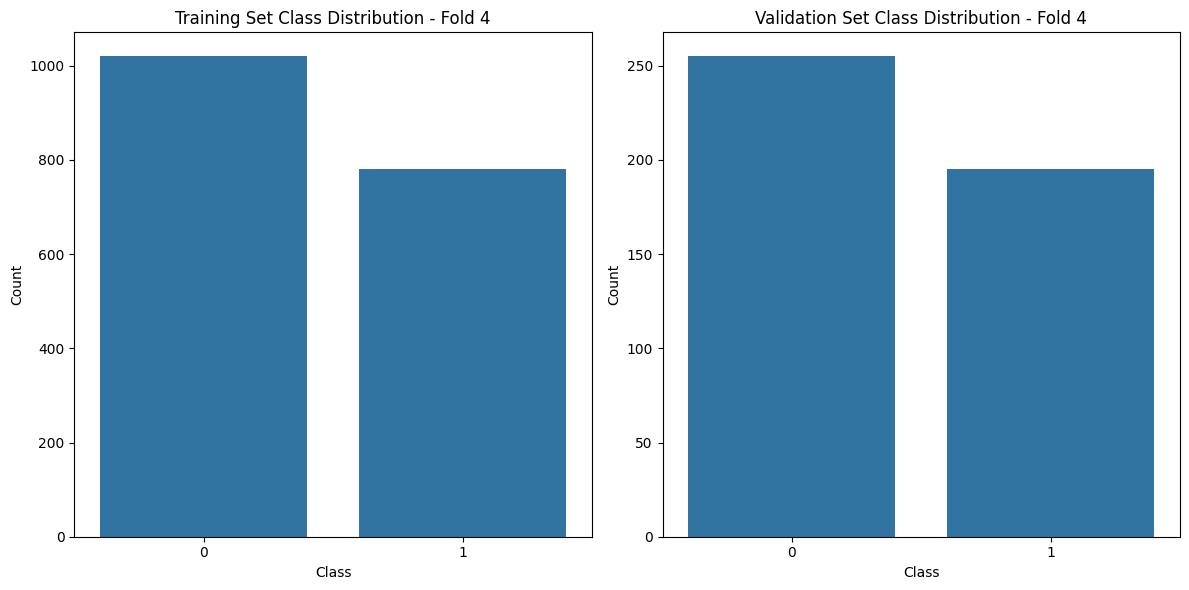

Epoch 1/5


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


56/56 ━━━━━━━━━━━━━━━━━━━━ 95s 2s/step - accuracy: 0.5255 - loss: 0.8958 - val_accuracy: 0.5692 - val_loss: 0.6850
Epoch 2/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 91s 2s/step - accuracy: 0.5692 - loss: 0.6872 - val_accuracy: 0.5647 - val_loss: 0.6847
Epoch 3/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 92s 2s/step - accuracy: 0.5915 - loss: 0.6776 - val_accuracy: 0.5670 - val_loss: 0.6895
Epoch 4/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 97s 2s/step - accuracy: 0.5724 - loss: 0.6866 - val_accuracy: 0.5670 - val_loss: 0.6842
Epoch 5/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 93s 2s/step - accuracy: 0.5670 - loss: 0.6840 - val_accuracy: 0.5647 - val_loss: 0.6847
14/14 ━━━━━━━━━━━━━━━━━━━━ 11s 762ms/step - accuracy: 0.5603 - loss: 0.6859
Validation Accuracy for fold 4: 0.5670
Classification Report for fold 5
Training fold 5...


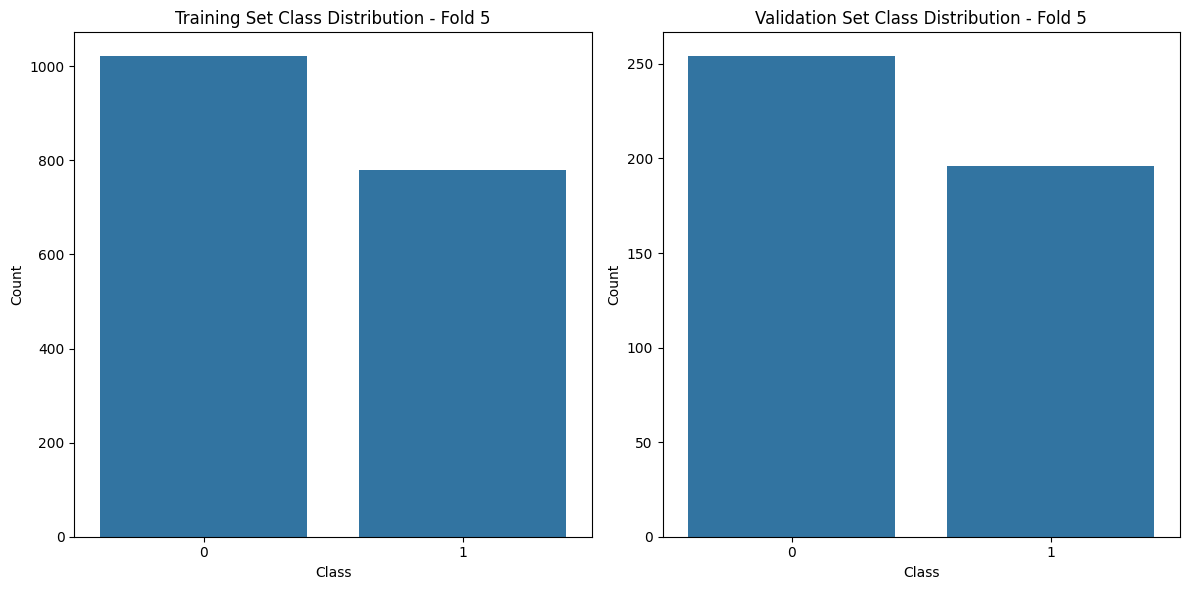

Epoch 1/5


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


56/56 ━━━━━━━━━━━━━━━━━━━━ 95s 2s/step - accuracy: 0.5472 - loss: 1.1629 - val_accuracy: 0.5625 - val_loss: 0.6667
Epoch 2/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 94s 2s/step - accuracy: 0.5669 - loss: 0.6899 - val_accuracy: 0.5625 - val_loss: 0.6859
Epoch 3/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 97s 2s/step - accuracy: 0.5667 - loss: 0.6855 - val_accuracy: 0.5647 - val_loss: 0.6848
Epoch 4/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 96s 2s/step - accuracy: 0.5543 - loss: 0.6879 - val_accuracy: 0.5647 - val_loss: 0.6850
Epoch 5/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 99s 2s/step - accuracy: 0.5601 - loss: 0.6897 - val_accuracy: 0.5647 - val_loss: 0.6878
14/14 ━━━━━━━━━━━━━━━━━━━━ 11s 765ms/step - accuracy: 0.6126 - loss: 0.6678
Validation Accuracy for fold 5: 0.5647
Classification Report for fold 6


In [47]:
import ssl
import certifi
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import pandas as pd
import numpy as np
import os
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.models import Sequential,load_model
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import Sequence
from sklearn.model_selection import KFold

# Use certifi's certificates for SSL verification
ssl._create_default_https_context = ssl.create_default_context(cafile=certifi.where())

# Configuration
IMAGE_SIZE_ALEXNET = (227, 227)   
BATCH_SIZE = 32
NUM_CLASSES = 2  # Binary classification
NUM_EPOCHS = 5
LEARNING_RATE = 0.001
KFOLDS = 5  # Number of folds for cross-validation
IMAGE_DIR = '/Users/chandraprakashsaravanan/Documents/Chandru_Dissertation/a-brazilian-multilabel-ophthalmological-dataset-brset-1.0.0/ne_image'  # Replace with the correct path to the new directory

# Load the DataFrame
df_filtered = df_filtered

# Ensure filenames include extensions and are correct
df_filtered['image_id'] = df_filtered['image_id'].apply(lambda x: f"{x}.jpg" if not x.endswith(".jpg") else x)

# Custom Data Generator
class DataGenerator(Sequence):
    def __init__(self, dataframe, image_dir, batch_size, image_size, num_classes, shuffle=True):
        self.dataframe = dataframe
        self.image_dir = image_dir
        self.batch_size = batch_size
        self.image_size = image_size
        self.num_classes = num_classes
        self.shuffle = shuffle
        self.on_epoch_end()

    def __len__(self):
        return int(np.floor(len(self.dataframe) / self.batch_size))

    def __getitem__(self, index):
        indexes = self.indexes[index * self.batch_size:(index + 1) * self.batch_size]
        batch_df = self.dataframe.iloc[indexes]
        X, y = self.__data_generation(batch_df)
        return X, y

    def on_epoch_end(self):
        self.indexes = np.arange(len(self.dataframe))
        if self.shuffle:
            np.random.shuffle(self.indexes)

    def __data_generation(self, batch_df):
        X = np.empty((self.batch_size, *self.image_size, 3))
        y = np.empty((self.batch_size), dtype=int)
        for i, (_, row) in enumerate(batch_df.iterrows()):
            img_name = row['image_id']  # Adjust the extension if necessary
            img_path = os.path.join(self.image_dir, img_name)
            img = load_img(img_path, target_size=self.image_size)
            img = img_to_array(img) / 255.0  # Normalize the image
            X[i,] = img
            y[i] = row['DR_ICDR']

        return X, tf.keras.utils.to_categorical(y, num_classes=self.num_classes)

# AlexNet Model Definition
def create_alexnet_model(input_shape, num_classes):
    model = Sequential([
        tf.keras.Input(shape=input_shape),  # Explicitly define the input shape
        Conv2D(96, (11, 11), strides=4, padding='valid', activation='relu'),
        MaxPooling2D(pool_size=(3, 3), strides=2),
        Conv2D(256, (5, 5), padding='same', activation='relu'),
        MaxPooling2D(pool_size=(3, 3), strides=2),
        Conv2D(384, (3, 3), padding='same', activation='relu'),
        Conv2D(384, (3, 3), padding='same', activation='relu'),
        Conv2D(256, (3, 3), padding='same', activation='relu'),
        MaxPooling2D(pool_size=(3, 3), strides=2),
        Flatten(),
        Dense(4096, activation='relu'),
        Dropout(0.5),
        Dense(4096, activation='relu'),
        Dropout(0.5),
        Dense(num_classes, activation='softmax')
    ])
    
    model.compile(optimizer=Adam(learning_rate=LEARNING_RATE), loss='categorical_crossentropy', metrics=['accuracy'])
    return model

kf = KFold(n_splits=KFOLDS, shuffle=True, random_state=42)
fold_no = 1

for train_index, val_index in kf.split(df_filtered):
    print(f"Training fold {fold_no}...")
    
    train_df = df_filtered.iloc[train_index]
    val_df = df_filtered.iloc[val_index]

    # Visualize the class distribution for training and validation data
    plt.figure(figsize=(12, 6))

    plt.subplot(1, 2, 1)
    sns.countplot(x='DR_ICDR', data=train_df)
    plt.title(f'Training Set Class Distribution - Fold {fold_no}')
    plt.xlabel('Class')
    plt.ylabel('Count')

    plt.subplot(1, 2, 2)
    sns.countplot(x='DR_ICDR', data=val_df)
    plt.title(f'Validation Set Class Distribution - Fold {fold_no}')
    plt.xlabel('Class')
    plt.ylabel('Count')

    plt.tight_layout()
    plt.show()
    
    train_generator_alexnet = DataGenerator(train_df, IMAGE_DIR, BATCH_SIZE, IMAGE_SIZE_ALEXNET, NUM_CLASSES)
    validation_generator_alexnet = DataGenerator(val_df, IMAGE_DIR, BATCH_SIZE, IMAGE_SIZE_ALEXNET, NUM_CLASSES)
    
    # Create a new instance of the model for each fold
    model_alexnet = create_alexnet_model((*IMAGE_SIZE_ALEXNET, 3), NUM_CLASSES)
    
    # Train the model
    history = model_alexnet.fit(
        train_generator_alexnet,
        epochs=NUM_EPOCHS,
        validation_data=validation_generator_alexnet
    )
    
    # Evaluate the model
    val_loss, val_accuracy = model_alexnet.evaluate(validation_generator_alexnet)
    print(f"Validation Accuracy for fold {fold_no}: {val_accuracy:.4f}")

    print(f"Classification Report for fold {fold_no+1}")

    # Save the model
    model_alexnet.save(f'alexnet_model_fold_{fold_no}.keras')
    
    fold_no += 1


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 493ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 234ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 224ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 225ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 225ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 224ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 226ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 225ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 225ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 224ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 223ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 223ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 224ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 224ms/step
y_pred shape: (448, 2)
First few y_pred values:
[[0.60339534 0.39660463]
 [0.60339534 0.39660463]
 [0.60339534 0.39660463]
 [0.60339534 0.39660463]
 [0.60339534 0.39660463]]
y_true: [1, 0, 1, 1, 0]
y_pred_classes: [0 0 0 0 0]
              precision    recall  f1-score   support

           0       0.56      1.00      0.72       253
           1       0.00      0.00      0.00       195

    accuracy                           0.56       448
   macro a

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  

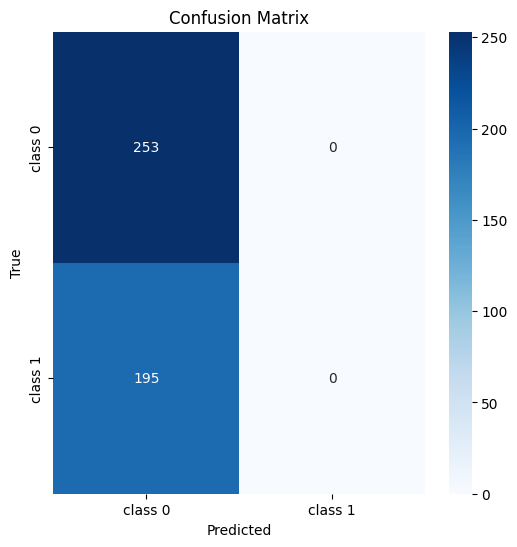

y_true_binarized shape: (448, 2)


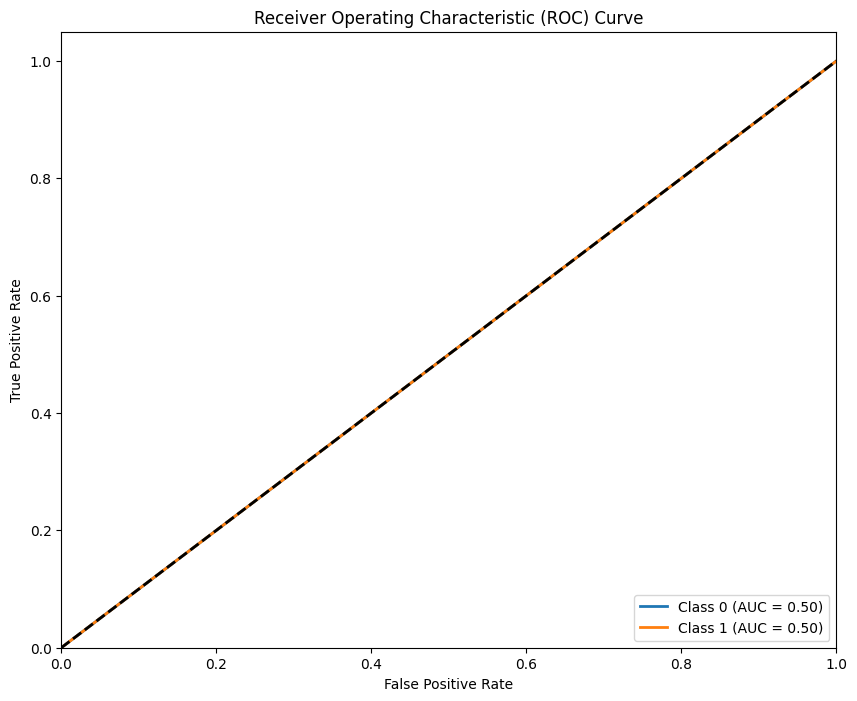

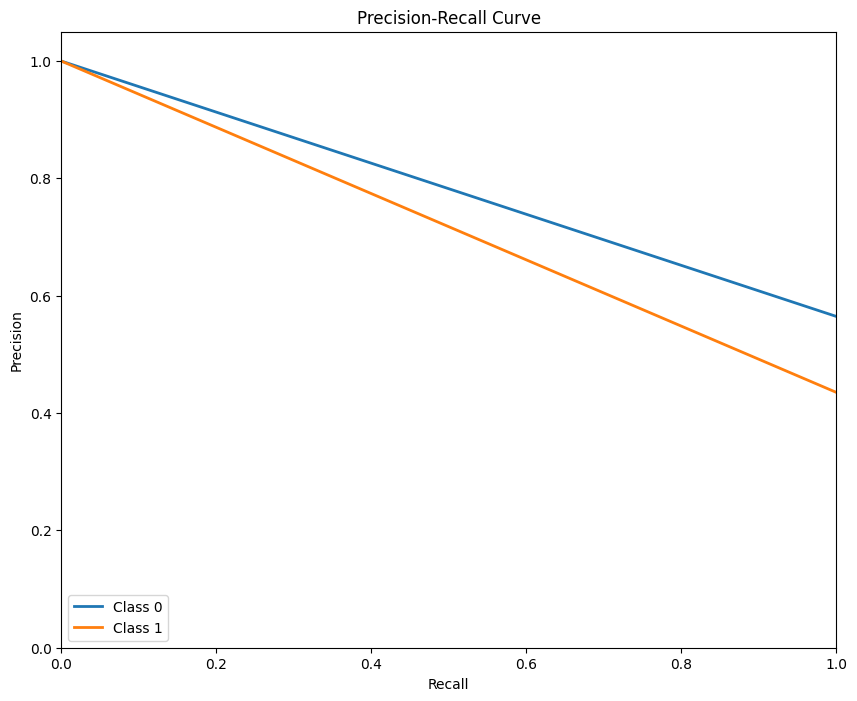

In [48]:
generate_classification_report_roc_pr(model_alexnet, validation_generator_alexnet)

Training fold 1...


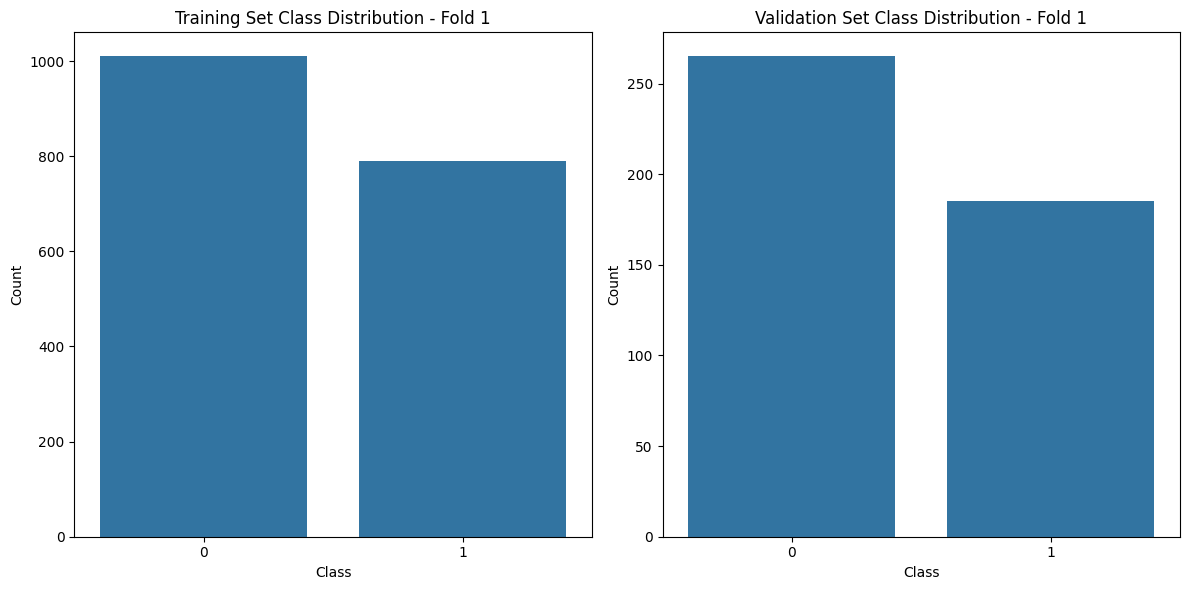

Epoch 1/5


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


56/56 ━━━━━━━━━━━━━━━━━━━━ 273s 5s/step - accuracy: 0.5253 - loss: 5.1281 - val_accuracy: 0.6830 - val_loss: 0.5845
Epoch 2/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 323s 6s/step - accuracy: 0.6520 - loss: 0.6809 - val_accuracy: 0.7031 - val_loss: 0.5660
Epoch 3/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 306s 5s/step - accuracy: 0.7368 - loss: 0.5173 - val_accuracy: 0.7366 - val_loss: 0.5150
Epoch 4/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 381s 7s/step - accuracy: 0.7891 - loss: 0.4379 - val_accuracy: 0.7210 - val_loss: 0.5136
Epoch 5/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 325s 6s/step - accuracy: 0.8166 - loss: 0.3987 - val_accuracy: 0.7188 - val_loss: 0.5742
14/14 ━━━━━━━━━━━━━━━━━━━━ 62s 4s/step - accuracy: 0.7355 - loss: 0.5587
Validation Accuracy for fold 1: 0.7210
Training fold 2...


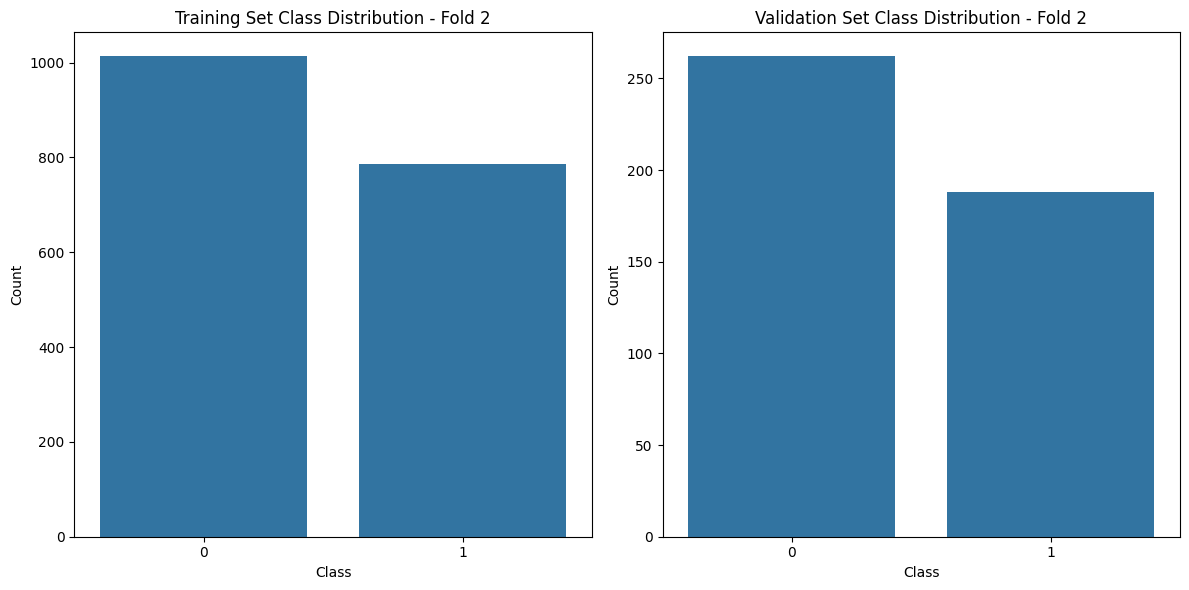

Epoch 1/5


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


56/56 ━━━━━━━━━━━━━━━━━━━━ 324s 6s/step - accuracy: 0.5391 - loss: 4.5399 - val_accuracy: 0.6384 - val_loss: 0.6254
Epoch 2/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 327s 6s/step - accuracy: 0.6683 - loss: 0.5988 - val_accuracy: 0.6674 - val_loss: 0.5859
Epoch 3/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 377s 7s/step - accuracy: 0.7326 - loss: 0.5267 - val_accuracy: 0.7121 - val_loss: 0.5456
Epoch 4/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 382s 7s/step - accuracy: 0.7723 - loss: 0.4739 - val_accuracy: 0.7076 - val_loss: 0.5304
Epoch 5/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 387s 7s/step - accuracy: 0.7790 - loss: 0.4657 - val_accuracy: 0.6741 - val_loss: 0.5867
14/14 ━━━━━━━━━━━━━━━━━━━━ 80s 6s/step - accuracy: 0.6802 - loss: 0.5843
Validation Accuracy for fold 2: 0.6741
Training fold 3...


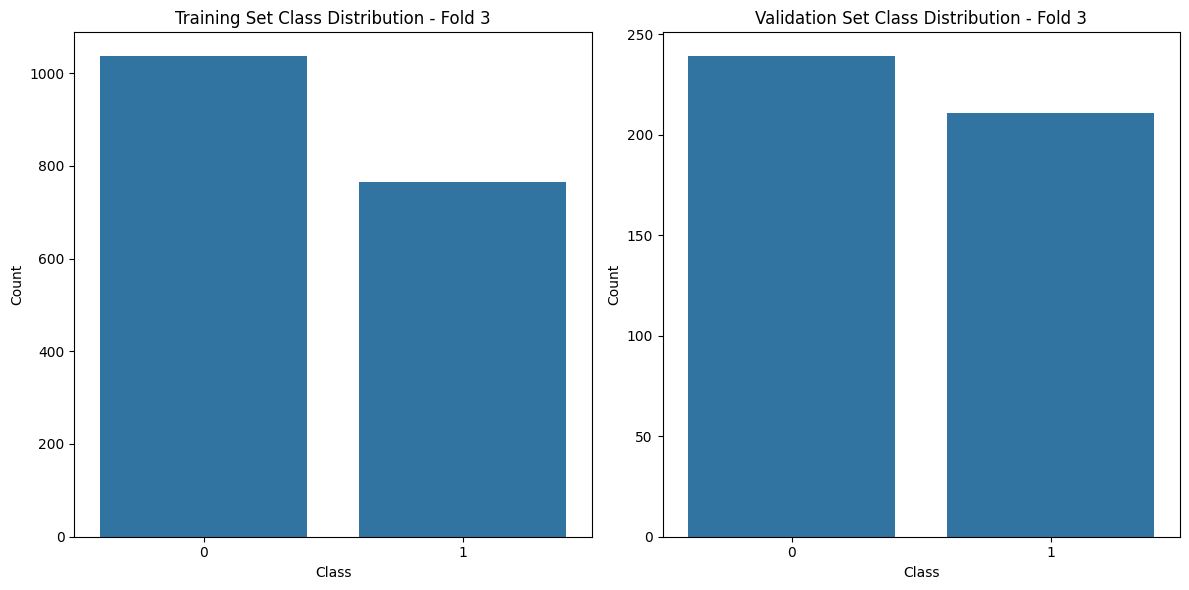

Epoch 1/5


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


56/56 ━━━━━━━━━━━━━━━━━━━━ 380s 7s/step - accuracy: 0.5289 - loss: 4.7517 - val_accuracy: 0.5826 - val_loss: 0.7055
Epoch 2/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 370s 7s/step - accuracy: 0.6786 - loss: 0.5880 - val_accuracy: 0.5804 - val_loss: 0.8305
Epoch 3/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 357s 6s/step - accuracy: 0.7164 - loss: 0.5432 - val_accuracy: 0.7121 - val_loss: 0.5631
Epoch 4/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 369s 7s/step - accuracy: 0.7955 - loss: 0.4297 - val_accuracy: 0.6362 - val_loss: 0.6827
Epoch 5/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 359s 6s/step - accuracy: 0.7955 - loss: 0.4450 - val_accuracy: 0.7054 - val_loss: 0.5841
14/14 ━━━━━━━━━━━━━━━━━━━━ 63s 5s/step - accuracy: 0.7012 - loss: 0.5810
Validation Accuracy for fold 3: 0.7054
Training fold 4...


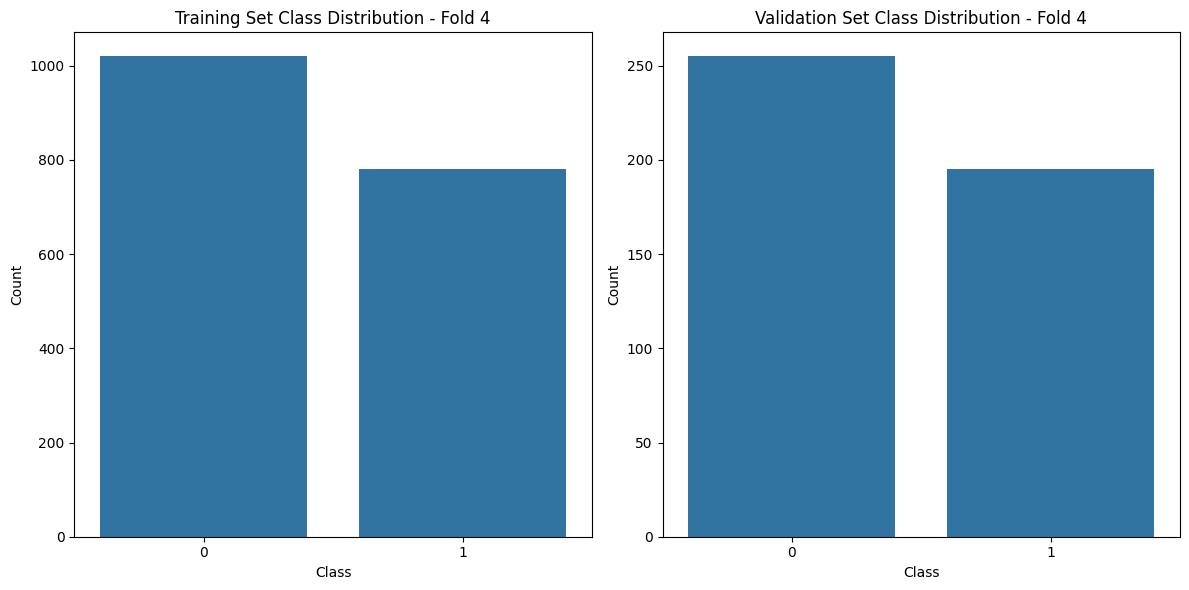

Epoch 1/5


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


56/56 ━━━━━━━━━━━━━━━━━━━━ 1028s 19s/step - accuracy: 0.5437 - loss: 4.6932 - val_accuracy: 0.6897 - val_loss: 0.5680
Epoch 2/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 330s 6s/step - accuracy: 0.7070 - loss: 0.6016 - val_accuracy: 0.7299 - val_loss: 0.5471
Epoch 3/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 323s 6s/step - accuracy: 0.7885 - loss: 0.4648 - val_accuracy: 0.6183 - val_loss: 0.7765
Epoch 4/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 333s 6s/step - accuracy: 0.7759 - loss: 0.4624 - val_accuracy: 0.7545 - val_loss: 0.4815
Epoch 5/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 552s 10s/step - accuracy: 0.7826 - loss: 0.4417 - val_accuracy: 0.6161 - val_loss: 0.8561
14/14 ━━━━━━━━━━━━━━━━━━━━ 178s 13s/step - accuracy: 0.5699 - loss: 0.9521
Validation Accuracy for fold 4: 0.6161
Training fold 5...


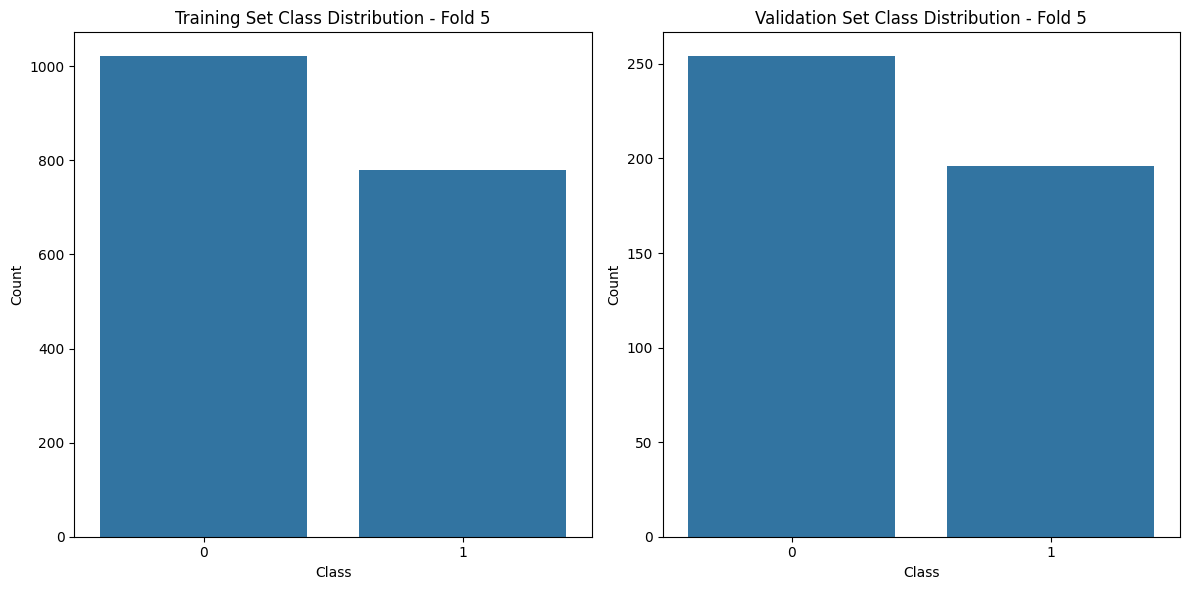

Epoch 1/5


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


56/56 ━━━━━━━━━━━━━━━━━━━━ 309s 5s/step - accuracy: 0.5342 - loss: 4.0830 - val_accuracy: 0.6786 - val_loss: 0.6163
Epoch 2/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 334s 6s/step - accuracy: 0.6959 - loss: 0.5846 - val_accuracy: 0.5268 - val_loss: 0.7963
Epoch 3/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 327s 6s/step - accuracy: 0.6801 - loss: 0.5961 - val_accuracy: 0.7009 - val_loss: 0.5507
Epoch 4/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 1327s 24s/step - accuracy: 0.7759 - loss: 0.4689 - val_accuracy: 0.7478 - val_loss: 0.5136
Epoch 5/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 943s 17s/step - accuracy: 0.7869 - loss: 0.4512 - val_accuracy: 0.6518 - val_loss: 0.6278
14/14 ━━━━━━━━━━━━━━━━━━━━ 311s 24s/step - accuracy: 0.6489 - loss: 0.6321
Validation Accuracy for fold 5: 0.6518


In [54]:
import ssl
import certifi
import os
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import pandas as pd
from tensorflow.keras.applications import VGG16
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Flatten
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import Sequence
from sklearn.model_selection import KFold

# Use certifi's certificates for SSL verification
ssl._create_default_https_context = ssl.create_default_context(cafile=certifi.where())

# Configuration
IMAGE_SIZE_VGG16 = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = 2
NUM_EPOCHS = 5
LEARNING_RATE = 0.001
KFOLDS = 5
IMAGE_DIR = '/Users/chandraprakashsaravanan/Documents/Chandru_Dissertation/a-brazilian-multilabel-ophthalmological-dataset-brset-1.0.0/ne_image'  # Replace with the correct path to your image directory
MODEL_SAVE_PATH = '/Users/chandraprakashsaravanan/Documents/Chandru_Dissertation/a-brazilian-multilabel-ophthalmological-dataset-brset-1.0.0/vgg16_model_fold_'  # Path prefix to save models

# Load the DataFrame (assuming df_filtered is already loaded with your data)
df_filtered = df_filtered.copy()

# Ensure filenames include extensions and are correct
df_filtered['image_id'] = df_filtered['image_id'].apply(lambda x: f"{x}.jpg" if not x.endswith(".jpg") else x)

# Custom Data Generator
class DataGenerator(Sequence):
    def __init__(self, dataframe, image_dir, batch_size, image_size, num_classes, shuffle=True):
        self.dataframe = dataframe
        self.image_dir = image_dir
        self.batch_size = batch_size
        self.image_size = image_size
        self.num_classes = num_classes
        self.shuffle = shuffle
        self.on_epoch_end()

    def __len__(self):
        return int(np.floor(len(self.dataframe) / self.batch_size))

    def __getitem__(self, index):
        indexes = self.indexes[index * self.batch_size:(index + 1) * self.batch_size]
        batch_df = self.dataframe.iloc[indexes]
        X, y = self.__data_generation(batch_df)
        return X, y

    def on_epoch_end(self):
        self.indexes = np.arange(len(self.dataframe))
        if self.shuffle:
            np.random.shuffle(self.indexes)

    def __data_generation(self, batch_df):
        X = np.empty((self.batch_size, *self.image_size, 3))
        y = np.empty((self.batch_size), dtype=int)
        for i, (_, row) in enumerate(batch_df.iterrows()):
            img_name = row['image_id']
            img_path = os.path.join(self.image_dir, img_name)
            img = load_img(img_path, target_size=self.image_size)
            img = img_to_array(img) / 255.0
            X[i,] = img
            y[i] = row['DR_ICDR']

        return X, tf.keras.utils.to_categorical(y, num_classes=self.num_classes)

# Load VGG16 Model with ImageNet Weights
def create_vgg16_model():
    base_model_vgg16 = VGG16(weights='imagenet', include_top=False, input_shape=(*IMAGE_SIZE_VGG16, 3))
    x_vgg16 = base_model_vgg16.output
    x_vgg16 = Flatten()(x_vgg16) 
    x_vgg16 = Dense(1024, activation='relu')(x_vgg16)
    predictions_vgg16 = Dense(NUM_CLASSES, activation='softmax')(x_vgg16)

    model_vgg16 = Model(inputs=base_model_vgg16.input, outputs=predictions_vgg16)

    for layer in base_model_vgg16.layers:
        layer.trainable = False

    model_vgg16.compile(optimizer=Adam(learning_rate=LEARNING_RATE), loss='categorical_crossentropy', metrics=['accuracy'])
    
    return model_vgg16

# K-Fold Cross-Validation
kf = KFold(n_splits=KFOLDS, shuffle=True, random_state=42)
fold_no = 1

for train_index, val_index in kf.split(df_filtered):
    print(f"Training fold {fold_no}...")


    train_df = df_filtered.iloc[train_index]
    val_df = df_filtered.iloc[val_index]

    # Visualize the class distribution for training and validation data
    plt.figure(figsize=(12, 6))

    plt.subplot(1, 2, 1)
    sns.countplot(x='DR_ICDR', data=train_df)
    plt.title(f'Training Set Class Distribution - Fold {fold_no}')
    plt.xlabel('Class')
    plt.ylabel('Count')

    plt.subplot(1, 2, 2)
    sns.countplot(x='DR_ICDR', data=val_df)
    plt.title(f'Validation Set Class Distribution - Fold {fold_no}')
    plt.xlabel('Class')
    plt.ylabel('Count')

    plt.tight_layout()
    plt.show()
    
    train_generator_vgg16 = DataGenerator(train_df, IMAGE_DIR, BATCH_SIZE, IMAGE_SIZE_VGG16, NUM_CLASSES)
    validation_generator_vgg16 = DataGenerator(val_df, IMAGE_DIR, BATCH_SIZE, IMAGE_SIZE_VGG16, NUM_CLASSES)
    
    model_vgg16 = create_vgg16_model()
    
    history = model_vgg16.fit(
        train_generator_vgg16,
        epochs=NUM_EPOCHS,
        validation_data=validation_generator_vgg16
    )
    
    val_loss, val_accuracy = model_vgg16.evaluate(validation_generator_vgg16)
    print(f"Validation Accuracy for fold {fold_no}: {val_accuracy:.4f}")
    
    model_vgg16.save(f'vgg16_model_fold_{fold_no}.keras')

    fold_no += 1


1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
y_pred shape: (448, 2)
First few y_pred values:
[[0.28459647 0.71540356]
 [0.87488395 0.125116  ]
 [0.2654934  0.73450655]
 [0.41598254 0.5840174 ]
 [0.35250044 0.64749956]]
y_true: [0, 0, 0, 0, 0]
y_pred_classes: [1 0 1 1 1]
              precision    recall  f1-score   support

           0       0.89      0.44      0.59       254
           1       0.56      0.93      0.70       194

    accuracy                           0.65       448
   macro avg       0.72      0.68      0.64       44

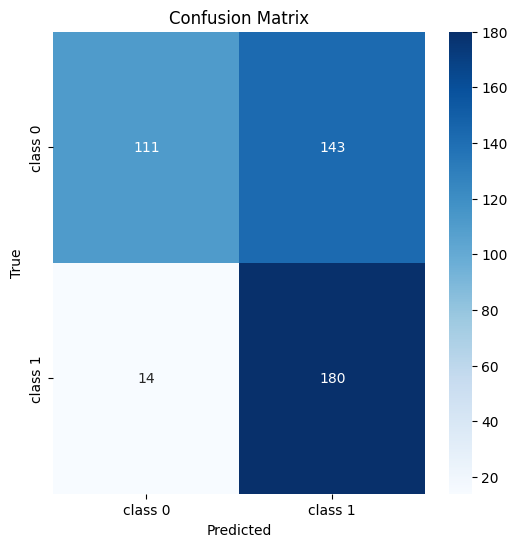

y_true_binarized shape: (448, 2)


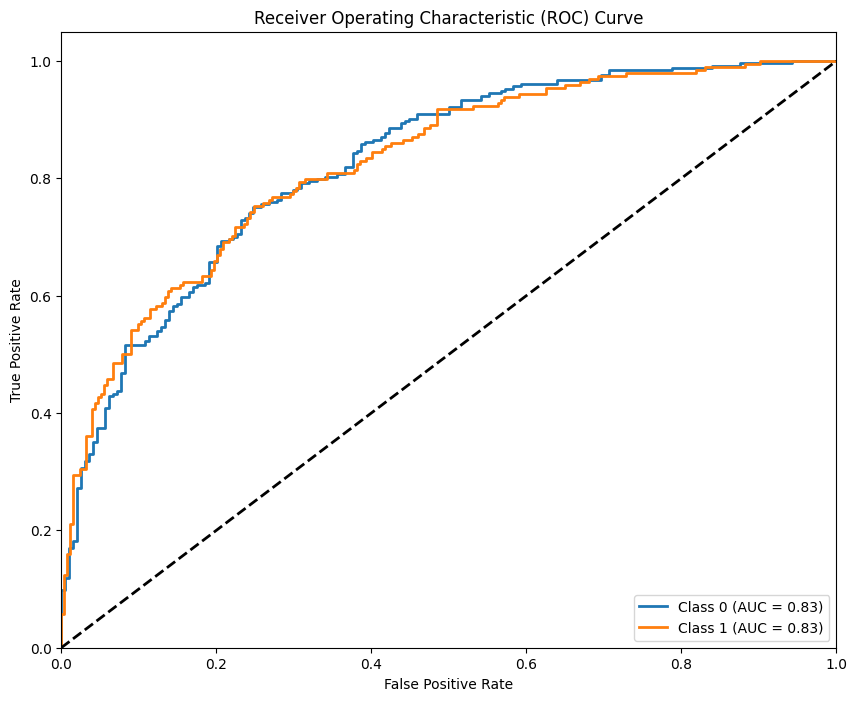

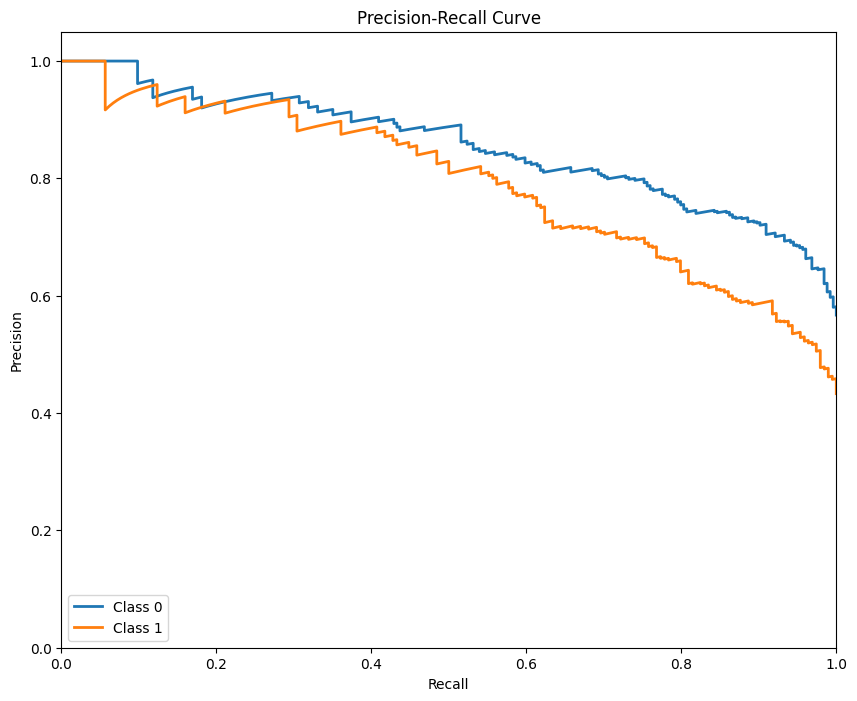

In [55]:
generate_classification_report_roc_pr(model_vgg16, validation_generator_vgg16)

Training fold 1...


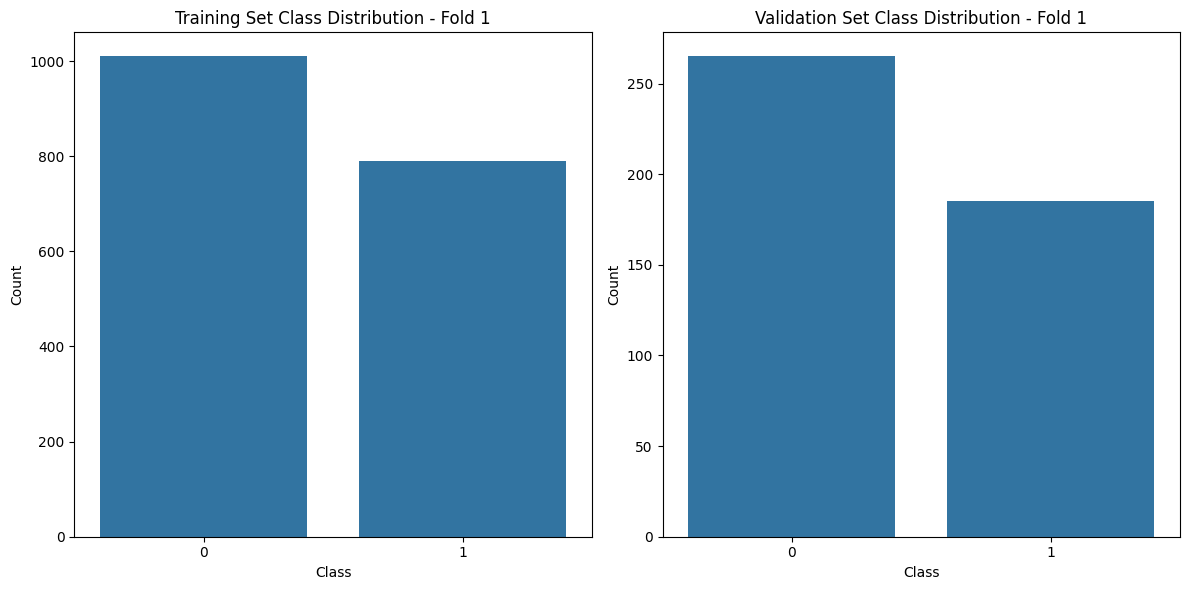

Epoch 1/5


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


56/56 ━━━━━━━━━━━━━━━━━━━━ 93s 2s/step - accuracy: 0.5124 - loss: 0.9360 - val_accuracy: 0.5893 - val_loss: 0.6850
Epoch 2/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 96s 2s/step - accuracy: 0.5185 - loss: 0.7119 - val_accuracy: 0.5893 - val_loss: 0.8243
Epoch 3/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 102s 2s/step - accuracy: 0.5194 - loss: 0.7764 - val_accuracy: 0.5915 - val_loss: 0.6746
Epoch 4/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 109s 2s/step - accuracy: 0.5165 - loss: 0.7385 - val_accuracy: 0.4107 - val_loss: 0.8375
Epoch 5/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 108s 2s/step - accuracy: 0.5261 - loss: 0.7247 - val_accuracy: 0.5871 - val_loss: 0.7546
14/14 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step - accuracy: 0.6031 - loss: 0.7354
Validation Accuracy for fold 1: 0.5871
Training fold 2...


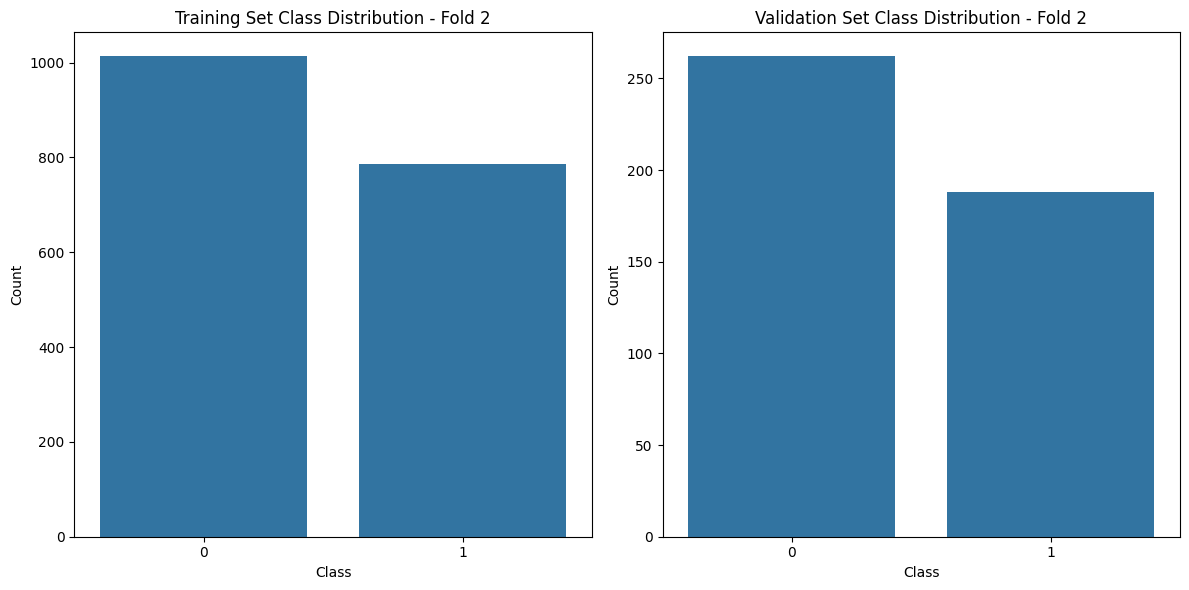

Epoch 1/5


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


56/56 ━━━━━━━━━━━━━━━━━━━━ 179s 3s/step - accuracy: 0.5184 - loss: 0.9572 - val_accuracy: 0.4174 - val_loss: 0.7262
Epoch 2/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 156s 3s/step - accuracy: 0.4967 - loss: 0.7329 - val_accuracy: 0.5804 - val_loss: 0.6778
Epoch 3/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 101s 2s/step - accuracy: 0.5441 - loss: 0.6968 - val_accuracy: 0.5603 - val_loss: 0.6904
Epoch 4/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 103s 2s/step - accuracy: 0.4990 - loss: 0.7114 - val_accuracy: 0.5826 - val_loss: 0.6762
Epoch 5/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 104s 2s/step - accuracy: 0.5309 - loss: 0.7470 - val_accuracy: 0.4219 - val_loss: 0.7022
14/14 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step - accuracy: 0.3874 - loss: 0.7060
Validation Accuracy for fold 2: 0.4174
Training fold 3...


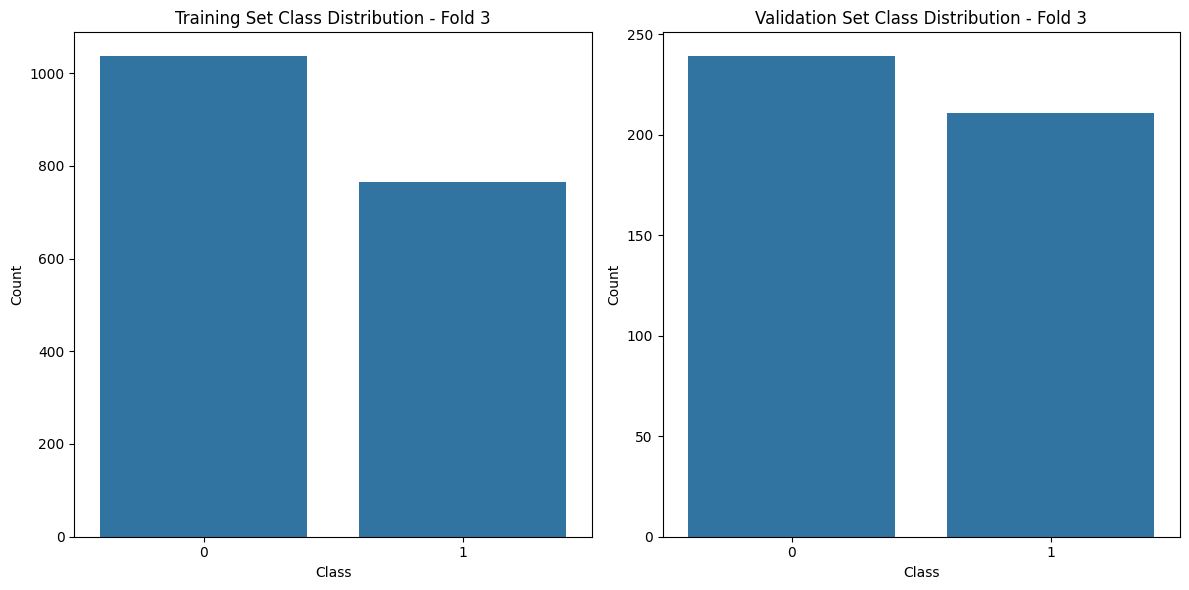

Epoch 1/5


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


56/56 ━━━━━━━━━━━━━━━━━━━━ 119s 2s/step - accuracy: 0.4921 - loss: 1.0158 - val_accuracy: 0.5312 - val_loss: 0.6898
Epoch 2/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 119s 2s/step - accuracy: 0.5350 - loss: 0.7080 - val_accuracy: 0.5312 - val_loss: 0.7746
Epoch 3/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 124s 2s/step - accuracy: 0.5371 - loss: 0.7109 - val_accuracy: 0.4888 - val_loss: 0.6908
Epoch 4/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 133s 2s/step - accuracy: 0.5282 - loss: 0.7027 - val_accuracy: 0.5290 - val_loss: 0.7113
Epoch 5/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 140s 2s/step - accuracy: 0.5646 - loss: 0.6884 - val_accuracy: 0.5290 - val_loss: 0.6873
14/14 ━━━━━━━━━━━━━━━━━━━━ 28s 2s/step - accuracy: 0.5335 - loss: 0.6878
Validation Accuracy for fold 3: 0.5268
Training fold 4...


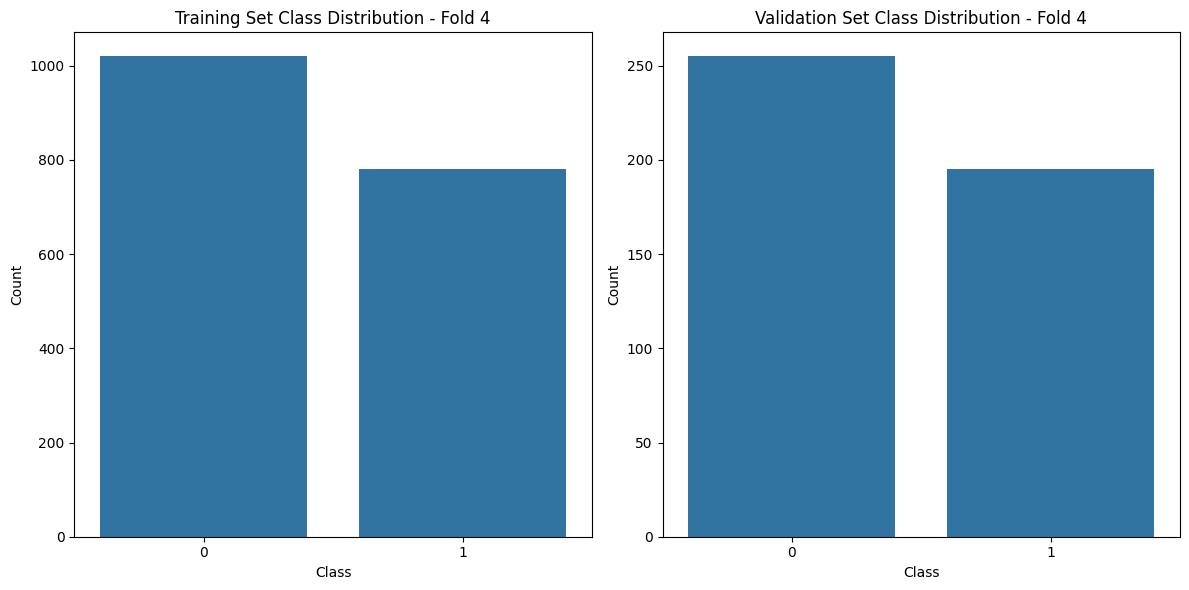

Epoch 1/5


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


56/56 ━━━━━━━━━━━━━━━━━━━━ 142s 2s/step - accuracy: 0.5112 - loss: 0.9561 - val_accuracy: 0.4330 - val_loss: 0.7050
Epoch 2/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 130s 2s/step - accuracy: 0.5055 - loss: 0.7137 - val_accuracy: 0.5670 - val_loss: 0.6796
Epoch 3/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 116s 2s/step - accuracy: 0.5117 - loss: 0.7357 - val_accuracy: 0.5692 - val_loss: 0.6863
Epoch 4/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 118s 2s/step - accuracy: 0.5588 - loss: 0.6949 - val_accuracy: 0.4308 - val_loss: 0.7026
Epoch 5/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 118s 2s/step - accuracy: 0.4940 - loss: 0.7239 - val_accuracy: 0.4353 - val_loss: 0.7024
14/14 ━━━━━━━━━━━━━━━━━━━━ 22s 2s/step - accuracy: 0.4167 - loss: 0.7070
Validation Accuracy for fold 4: 0.4330
Training fold 5...


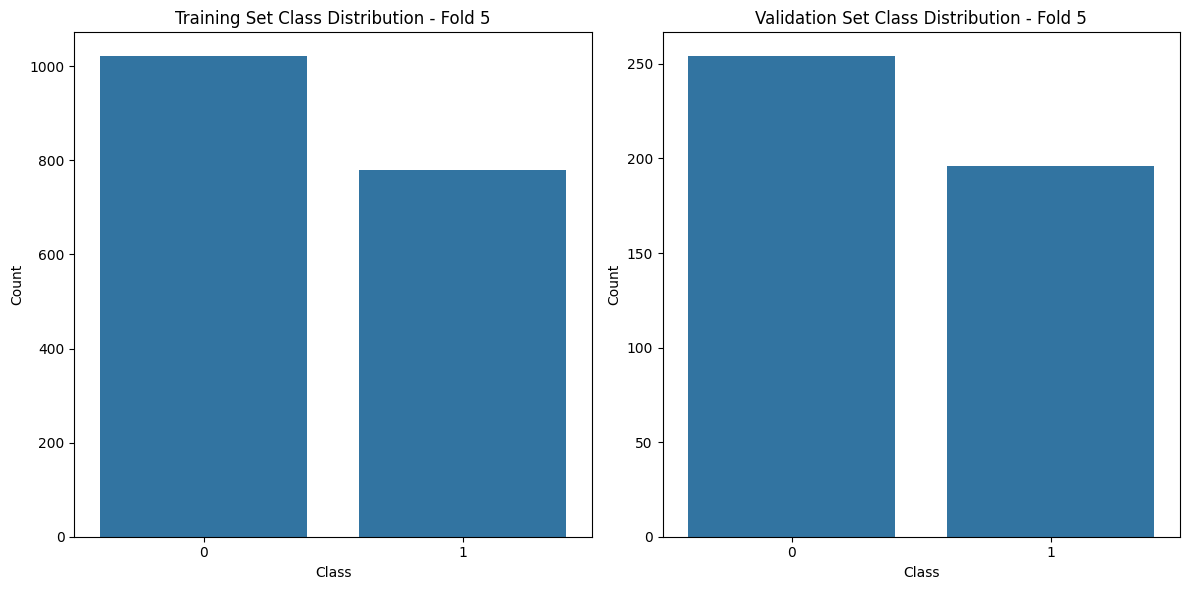

Epoch 1/5


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


56/56 ━━━━━━━━━━━━━━━━━━━━ 121s 2s/step - accuracy: 0.5218 - loss: 1.0799 - val_accuracy: 0.5625 - val_loss: 0.7205
Epoch 2/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 110s 2s/step - accuracy: 0.5255 - loss: 0.7036 - val_accuracy: 0.5625 - val_loss: 0.6834
Epoch 3/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 111s 2s/step - accuracy: 0.5283 - loss: 0.6979 - val_accuracy: 0.5647 - val_loss: 0.6915
Epoch 4/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 115s 2s/step - accuracy: 0.5340 - loss: 0.7075 - val_accuracy: 0.5647 - val_loss: 0.7314
Epoch 5/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 114s 2s/step - accuracy: 0.5498 - loss: 0.6998 - val_accuracy: 0.5647 - val_loss: 0.6793
14/14 ━━━━━━━━━━━━━━━━━━━━ 22s 2s/step - accuracy: 0.5677 - loss: 0.6794
Validation Accuracy for fold 5: 0.5670


In [58]:
import ssl
import certifi
import os
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import pandas as pd
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Flatten
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import Sequence
from sklearn.model_selection import KFold

# Use certifi's certificates for SSL verification
ssl._create_default_https_context = ssl.create_default_context(cafile=certifi.where())

# Configuration
IMAGE_SIZE_RESNET50 = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = 2
NUM_EPOCHS = 5
LEARNING_RATE = 0.001
KFOLDS = 5
IMAGE_DIR = '/Users/chandraprakashsaravanan/Documents/Chandru_Dissertation/a-brazilian-multilabel-ophthalmological-dataset-brset-1.0.0/ne_image'  # Replace with the correct path to your image directory
MODEL_SAVE_PATH = '/Users/chandraprakashsaravanan/Documents/Chandru_Dissertation/a-brazilian-multilabel-ophthalmological-dataset-brset-1.0.0/resnet50_model_fold_'  # Path prefix to save models

# Load the DataFrame (assuming df_filtered is already loaded with your data)
df_filtered = df_filtered.copy()

# Ensure filenames include extensions and are correct
df_filtered['image_id'] = df_filtered['image_id'].apply(lambda x: f"{x}.jpg" if not x.endswith(".jpg") else x)

# Custom Data Generator
class DataGenerator(Sequence):
    def __init__(self, dataframe, image_dir, batch_size, image_size, num_classes, shuffle=True):
        self.dataframe = dataframe
        self.image_dir = image_dir
        self.batch_size = batch_size
        self.image_size = image_size
        self.num_classes = num_classes
        self.shuffle = shuffle
        self.on_epoch_end()

    def __len__(self):
        return int(np.floor(len(self.dataframe) / self.batch_size))

    def __getitem__(self, index):
        indexes = self.indexes[index * self.batch_size:(index + 1) * self.batch_size]
        batch_df = self.dataframe.iloc[indexes]
        X, y = self.__data_generation(batch_df)
        return X, y

    def on_epoch_end(self):
        self.indexes = np.arange(len(self.dataframe))
        if self.shuffle:
            np.random.shuffle(self.indexes)

    def __data_generation(self, batch_df):
        X = np.empty((self.batch_size, *self.image_size, 3))
        y = np.empty((self.batch_size), dtype=int)
        for i, (_, row) in enumerate(batch_df.iterrows()):
            img_name = row['image_id']
            img_path = os.path.join(self.image_dir, img_name)
            img = load_img(img_path, target_size=self.image_size)
            img = img_to_array(img) / 255.0
            X[i,] = img
            y[i] = row['DR_ICDR']

        return X, tf.keras.utils.to_categorical(y, num_classes=self.num_classes)

# Load ResNet50 Model with ImageNet Weights
def create_resnet50_model():
    base_model_resnet50 = ResNet50(weights='imagenet', include_top=False, input_shape=(*IMAGE_SIZE_RESNET50, 3))
    x_resnet50 = base_model_resnet50.output
    x_resnet50 = GlobalAveragePooling2D()(x_resnet50)  # We use GAP instead of Flatten here
    x_resnet50 = Dense(1024, activation='relu')(x_resnet50)
    predictions_resnet50 = Dense(NUM_CLASSES, activation='softmax')(x_resnet50)

    model_resnet50 = Model(inputs=base_model_resnet50.input, outputs=predictions_resnet50)

    for layer in base_model_resnet50.layers:
        layer.trainable = False

    model_resnet50.compile(optimizer=Adam(learning_rate=LEARNING_RATE), loss='categorical_crossentropy', metrics=['accuracy'])
    
    return model_resnet50

# K-Fold Cross-Validation
kf = KFold(n_splits=KFOLDS, shuffle=True, random_state=42)
fold_no = 1

for train_index, val_index in kf.split(df_filtered):
    print(f"Training fold {fold_no}...")

    train_df = df_filtered.iloc[train_index]
    val_df = df_filtered.iloc[val_index]

    # Visualize the class distribution for training and validation data
    plt.figure(figsize=(12, 6))

    plt.subplot(1, 2, 1)
    sns.countplot(x='DR_ICDR', data=train_df)
    plt.title(f'Training Set Class Distribution - Fold {fold_no}')
    plt.xlabel('Class')
    plt.ylabel('Count')

    plt.subplot(1, 2, 2)
    sns.countplot(x='DR_ICDR', data=val_df)
    plt.title(f'Validation Set Class Distribution - Fold {fold_no}')
    plt.xlabel('Class')
    plt.ylabel('Count')

    plt.tight_layout()
    plt.show()
    
    train_generator_resnet50 = DataGenerator(train_df, IMAGE_DIR, BATCH_SIZE, IMAGE_SIZE_RESNET50, NUM_CLASSES)
    validation_generator_resnet50 = DataGenerator(val_df, IMAGE_DIR, BATCH_SIZE, IMAGE_SIZE_RESNET50, NUM_CLASSES)
    
    model_resnet50 = create_resnet50_model()
    
    history = model_resnet50.fit(
        train_generator_resnet50,
        epochs=NUM_EPOCHS,
        validation_data=validation_generator_resnet50
    )
    
    val_loss, val_accuracy = model_resnet50.evaluate(validation_generator_resnet50)
    print(f"Validation Accuracy for fold {fold_no}: {val_accuracy:.4f}")
    
    model_resnet50.save(f'{MODEL_SAVE_PATH}{fold_no}.keras')

    fold_no += 1


1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
y_pred shape: (448, 2)
First few y_pred values:
[[0.5531613  0.44683877]
 [0.53123057 0.46876943]
 [0.53358716 0.46641287]
 [0.5400769  0.45992303]
 [0.52642995 0.47357017]]
y_true: [1, 0, 1, 1, 1]
y_pred_classes: [0 0 0 0 0]
              precision    recall  f1-score   support

           0       0.57      0.98      0.72       253
           1       0.50      0.02      0.04       195

    accuracy                           0.56       448
   macro avg       0.53      0.50      0.38       44

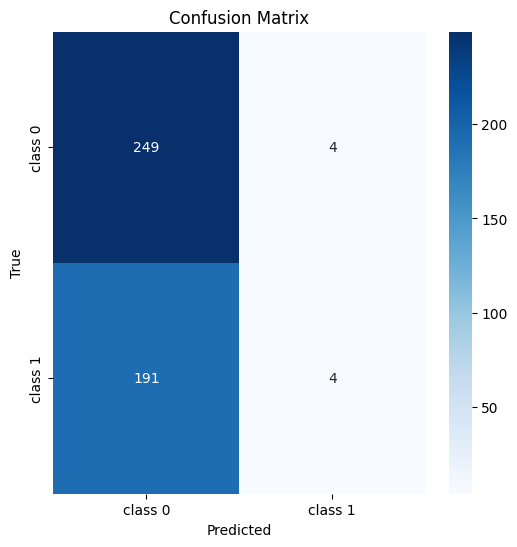

y_true_binarized shape: (448, 2)


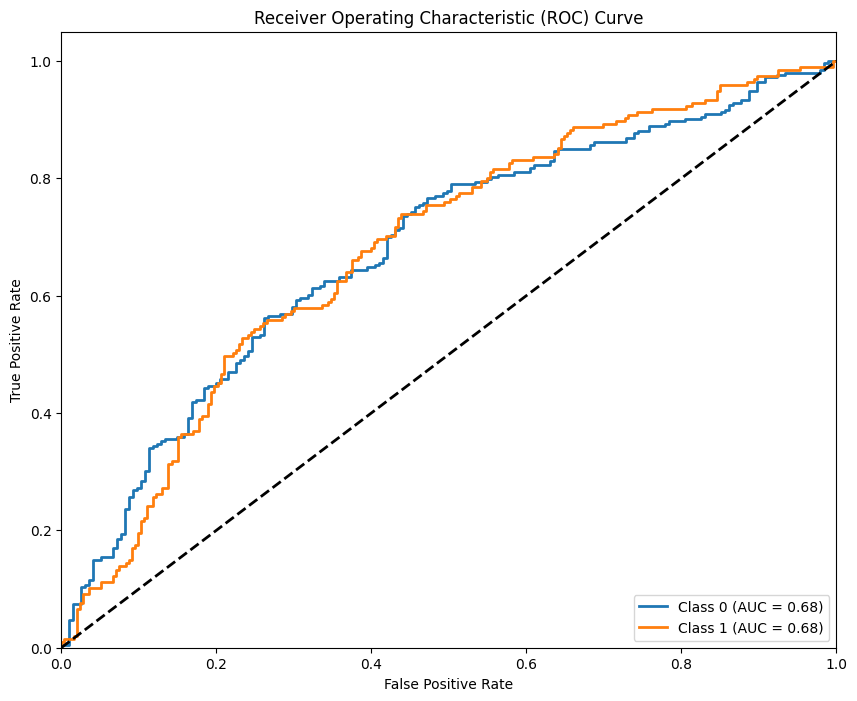

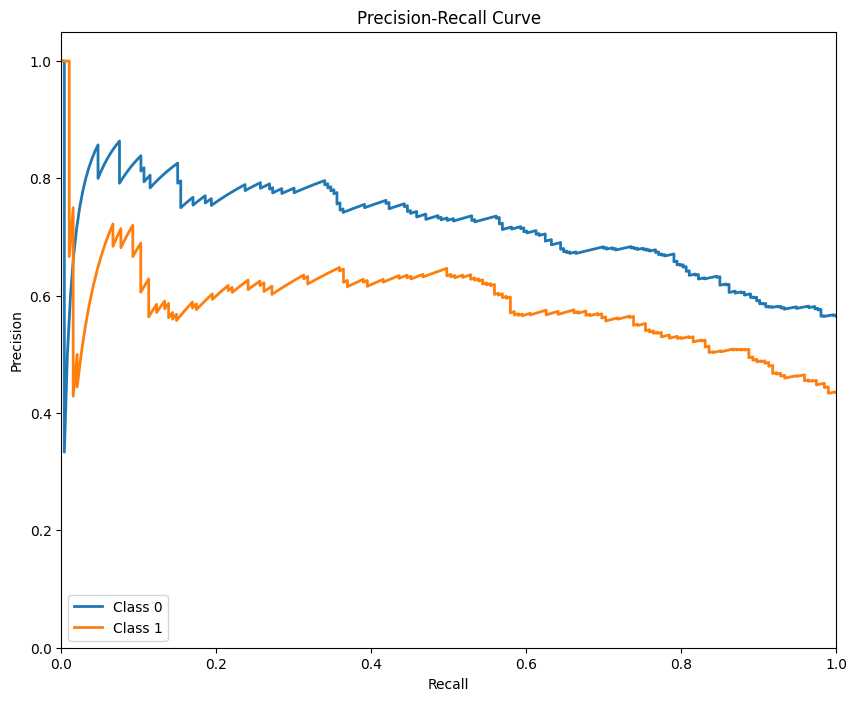

In [59]:
generate_classification_report_roc_pr(model_resnet50, validation_generator_resnet50)

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Classification Report for InceptionV3:

              precision    recall  f1-score   support

           0       0.79      0.94      0.86       253
           1       0.89      0.68      0.77       195

    accuracy                           0.82       448
   macro avg       0.84      0.81      0.81       448
weighted avg       0.83      0.82      0.82       448

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  

1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
Classification Report for VGG16:

              precision    recall  f1-score   support

           0       0.89      0.44      0.59       254
           1       0.56      0.93      0.70       194

    accuracy                           0.65       448
   macro avg       0.72      0.68      0.64       448
weighted avg       0.74      0.65      0.63       448

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s

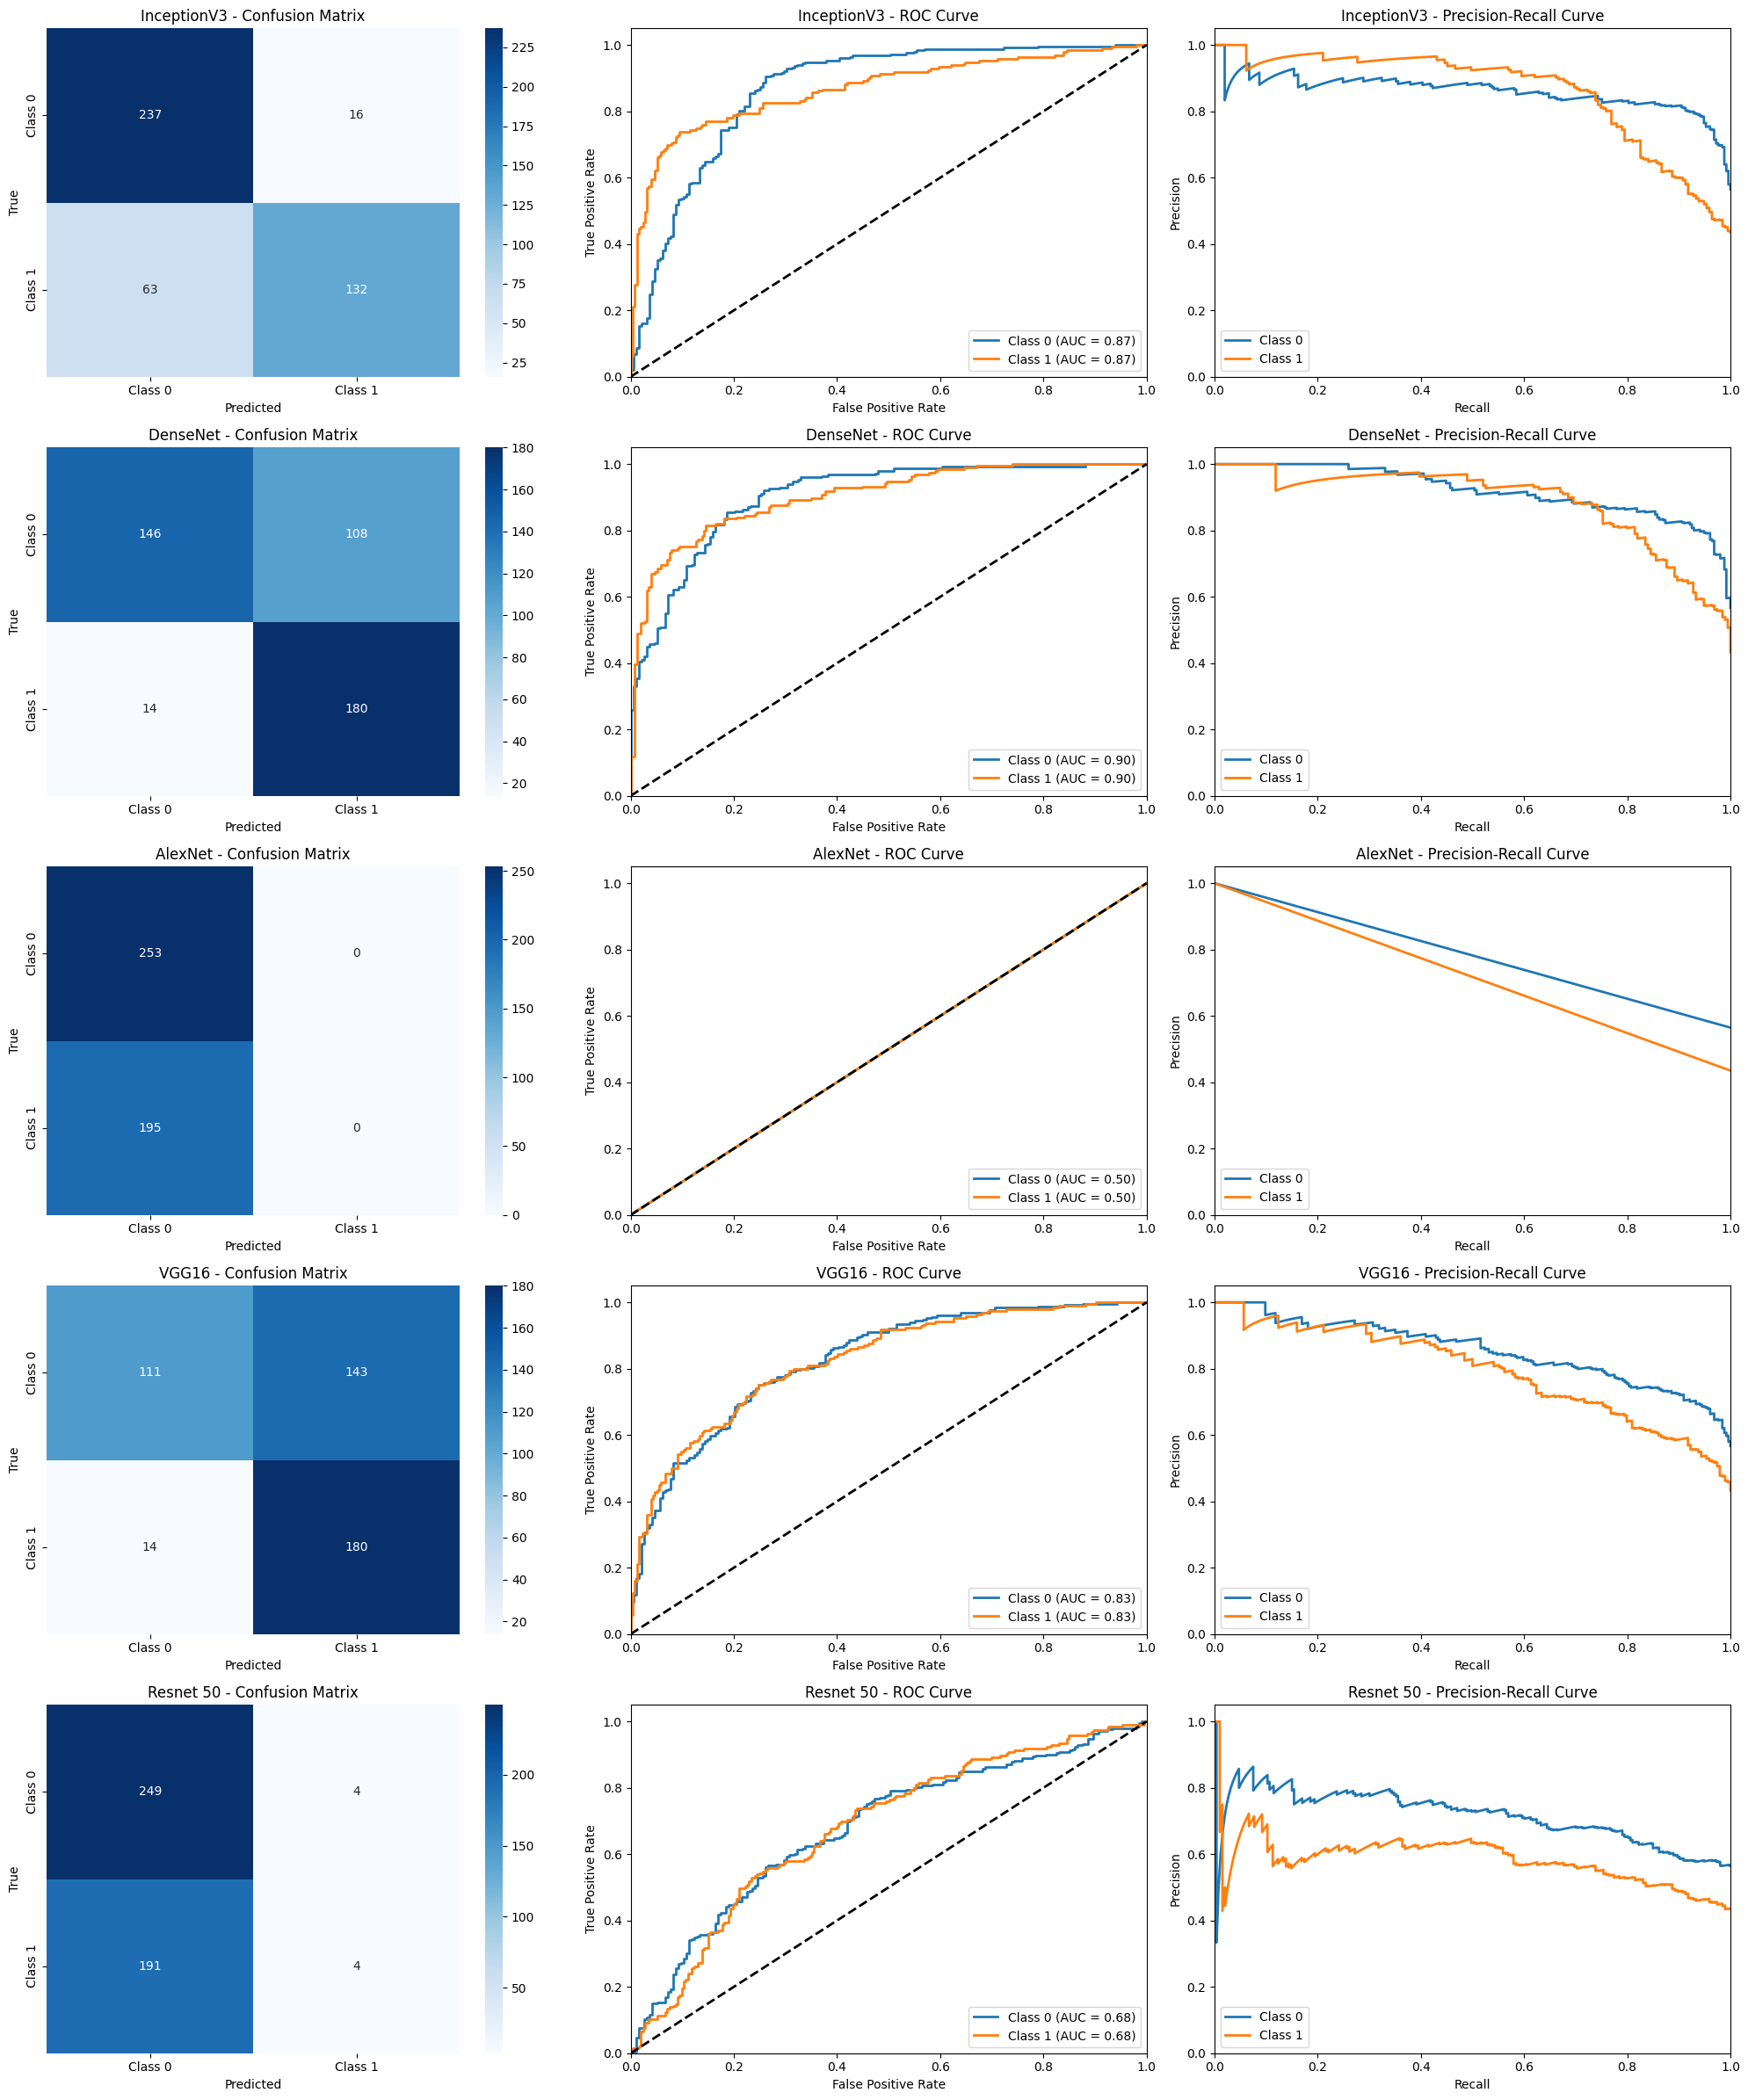

In [60]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import classification_report, roc_curve, auc, precision_recall_curve, confusion_matrix
from sklearn.preprocessing import label_binarize

# Modified function to collect plots
def generate_classification_report_graph(model, validation_generator, model_name, axes):
    y_true = []
    y_pred = []

    for i in range(len(validation_generator)):
        X, y = validation_generator[i]
        y_true.extend(np.argmax(y, axis=1))
        y_pred_batch = model.predict(X)

        # Ensure y_pred_batch has the correct shape
        if len(y_pred_batch.shape) == 1:
            # Convert single output to two-class probabilities
            y_pred_batch = np.vstack([1 - y_pred_batch, y_pred_batch]).T

        y_pred.extend(y_pred_batch)

    y_pred = np.array(y_pred)

    y_pred_classes = np.argmax(y_pred, axis=1)

    # Print classification report
    print(f"Classification Report for {model_name}:\n")
    print(classification_report(y_true, y_pred_classes))

    # Confusion Matrix
    conf_matrix = confusion_matrix(y_true, y_pred_classes)
    sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'], ax=axes[0])
    axes[0].set_xlabel('Predicted')
    axes[0].set_ylabel('True')
    axes[0].set_title(f'{model_name} - Confusion Matrix')

    # Generate ROC curve for both classes
    y_true_binarized = label_binarize(y_true, classes=[0, 1])

    if y_true_binarized.shape[1] == 1:
        y_true_binarized = np.hstack([1 - y_true_binarized, y_true_binarized])

    fpr = dict()
    tpr = dict()
    roc_auc = dict()

    for i in range(2):  # Binary classification: classes 0 and 1
        fpr[i], tpr[i], _ = roc_curve(y_true_binarized[:, i], y_pred[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    for i in range(2):  # Only for classes 0 and 1
        axes[1].plot(fpr[i], tpr[i], lw=2, label=f'Class {i} (AUC = {roc_auc[i]:0.2f})')
    axes[1].plot([0, 1], [0, 1], 'k--', lw=2)
    axes[1].set_xlim([0.0, 1.0])
    axes[1].set_ylim([0.0, 1.05])
    axes[1].set_xlabel('False Positive Rate')
    axes[1].set_ylabel('True Positive Rate')
    axes[1].set_title(f'{model_name} - ROC Curve')
    axes[1].legend(loc="lower right")

    # Generate Precision-Recall curve
    precision = dict()
    recall = dict()

    for i in range(2):
        precision[i], recall[i], _ = precision_recall_curve(y_true_binarized[:, i], y_pred[:, i])

    for i in range(2):
        axes[2].plot(recall[i], precision[i], lw=2, label=f'Class {i}')
    axes[2].set_xlim([0.0, 1.0])
    axes[2].set_ylim([0.0, 1.05])
    axes[2].set_xlabel('Recall')
    axes[2].set_ylabel('Precision')
    axes[2].set_title(f'{model_name} - Precision-Recall Curve')
    axes[2].legend(loc="lower left")

# Set up a grid for plots
fig, axes = plt.subplots(nrows=5, ncols=3, figsize=(20, 24))
axes = axes.flatten()

# Each model's axes will occupy 3 slots in the flattened array (3 plots per model)

generate_classification_report_graph(model_inception, validation_generator_inception, 'InceptionV3', axes[0:3])
generate_classification_report_graph(model_densenet, validation_generator_densenet, 'DenseNet', axes[3:6])
generate_classification_report_graph(model_alexnet, validation_generator_alexnet, 'AlexNet', axes[6:9])
generate_classification_report_graph(model_vgg16, validation_generator_vgg16, 'VGG16', axes[9:12])
generate_classification_report_graph(model_resnet50, validation_generator_resnet50, 'Resnet 50', axes[12:15])



plt.tight_layout()
plt.show()


In [62]:
pip install opencv-python

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.8/54.8 MB 40.1 MB/s eta 0:00:00a 0:00:01
Note: you may need to restart the kernel to use updated packages.


In [63]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from PIL import Image
import os
import random
import cv2

In [64]:
import pandas as pd
import os
import matplotlib.pyplot as plt
from PIL import Image

def display_images_for_patients(df, image_folder, num_patients=10, grid_size=(5, 4)):

    # Get the unique patient IDs
    unique_patient_ids = df['patient_id'].unique()[:num_patients]
    
    # Filter the dataset to only include the selected patients
    filtered_df = df[df['patient_id'].isin(unique_patient_ids)]
    
    # Set up the plot
    fig, axes = plt.subplots(grid_size[0], grid_size[1], figsize=(20, 20))
    
    # Flatten the axes array for easy iteration
    axes = axes.flatten()
    
    # Keep track of the number of images displayed
    img_count = 0
    
    for patient_id in unique_patient_ids:
        patient_images = filtered_df[filtered_df['patient_id'] == patient_id]
        
        for _, row in patient_images.iterrows():
            if img_count >= len(axes):
                break
            
            img_path = os.path.join(image_folder, row['image_id'])
            
            # Check if the image file exists
            if os.path.exists(img_path):
                # Open image
                img = Image.open(img_path)
                
                # Display image
                ax = axes[img_count]
                ax.imshow(img)
                ax.set_xlabel(f"Patient {patient_id}\n{row['image_id']}", fontsize=10)
                ax.yaxis.set_visible(False)
                img_count += 1
    
    # Hide remaining axes if there are any
    for ax in axes[img_count:]:
        ax.axis('off')
    
    # Adjust layout and show plot
    plt.tight_layout()
    plt.show()




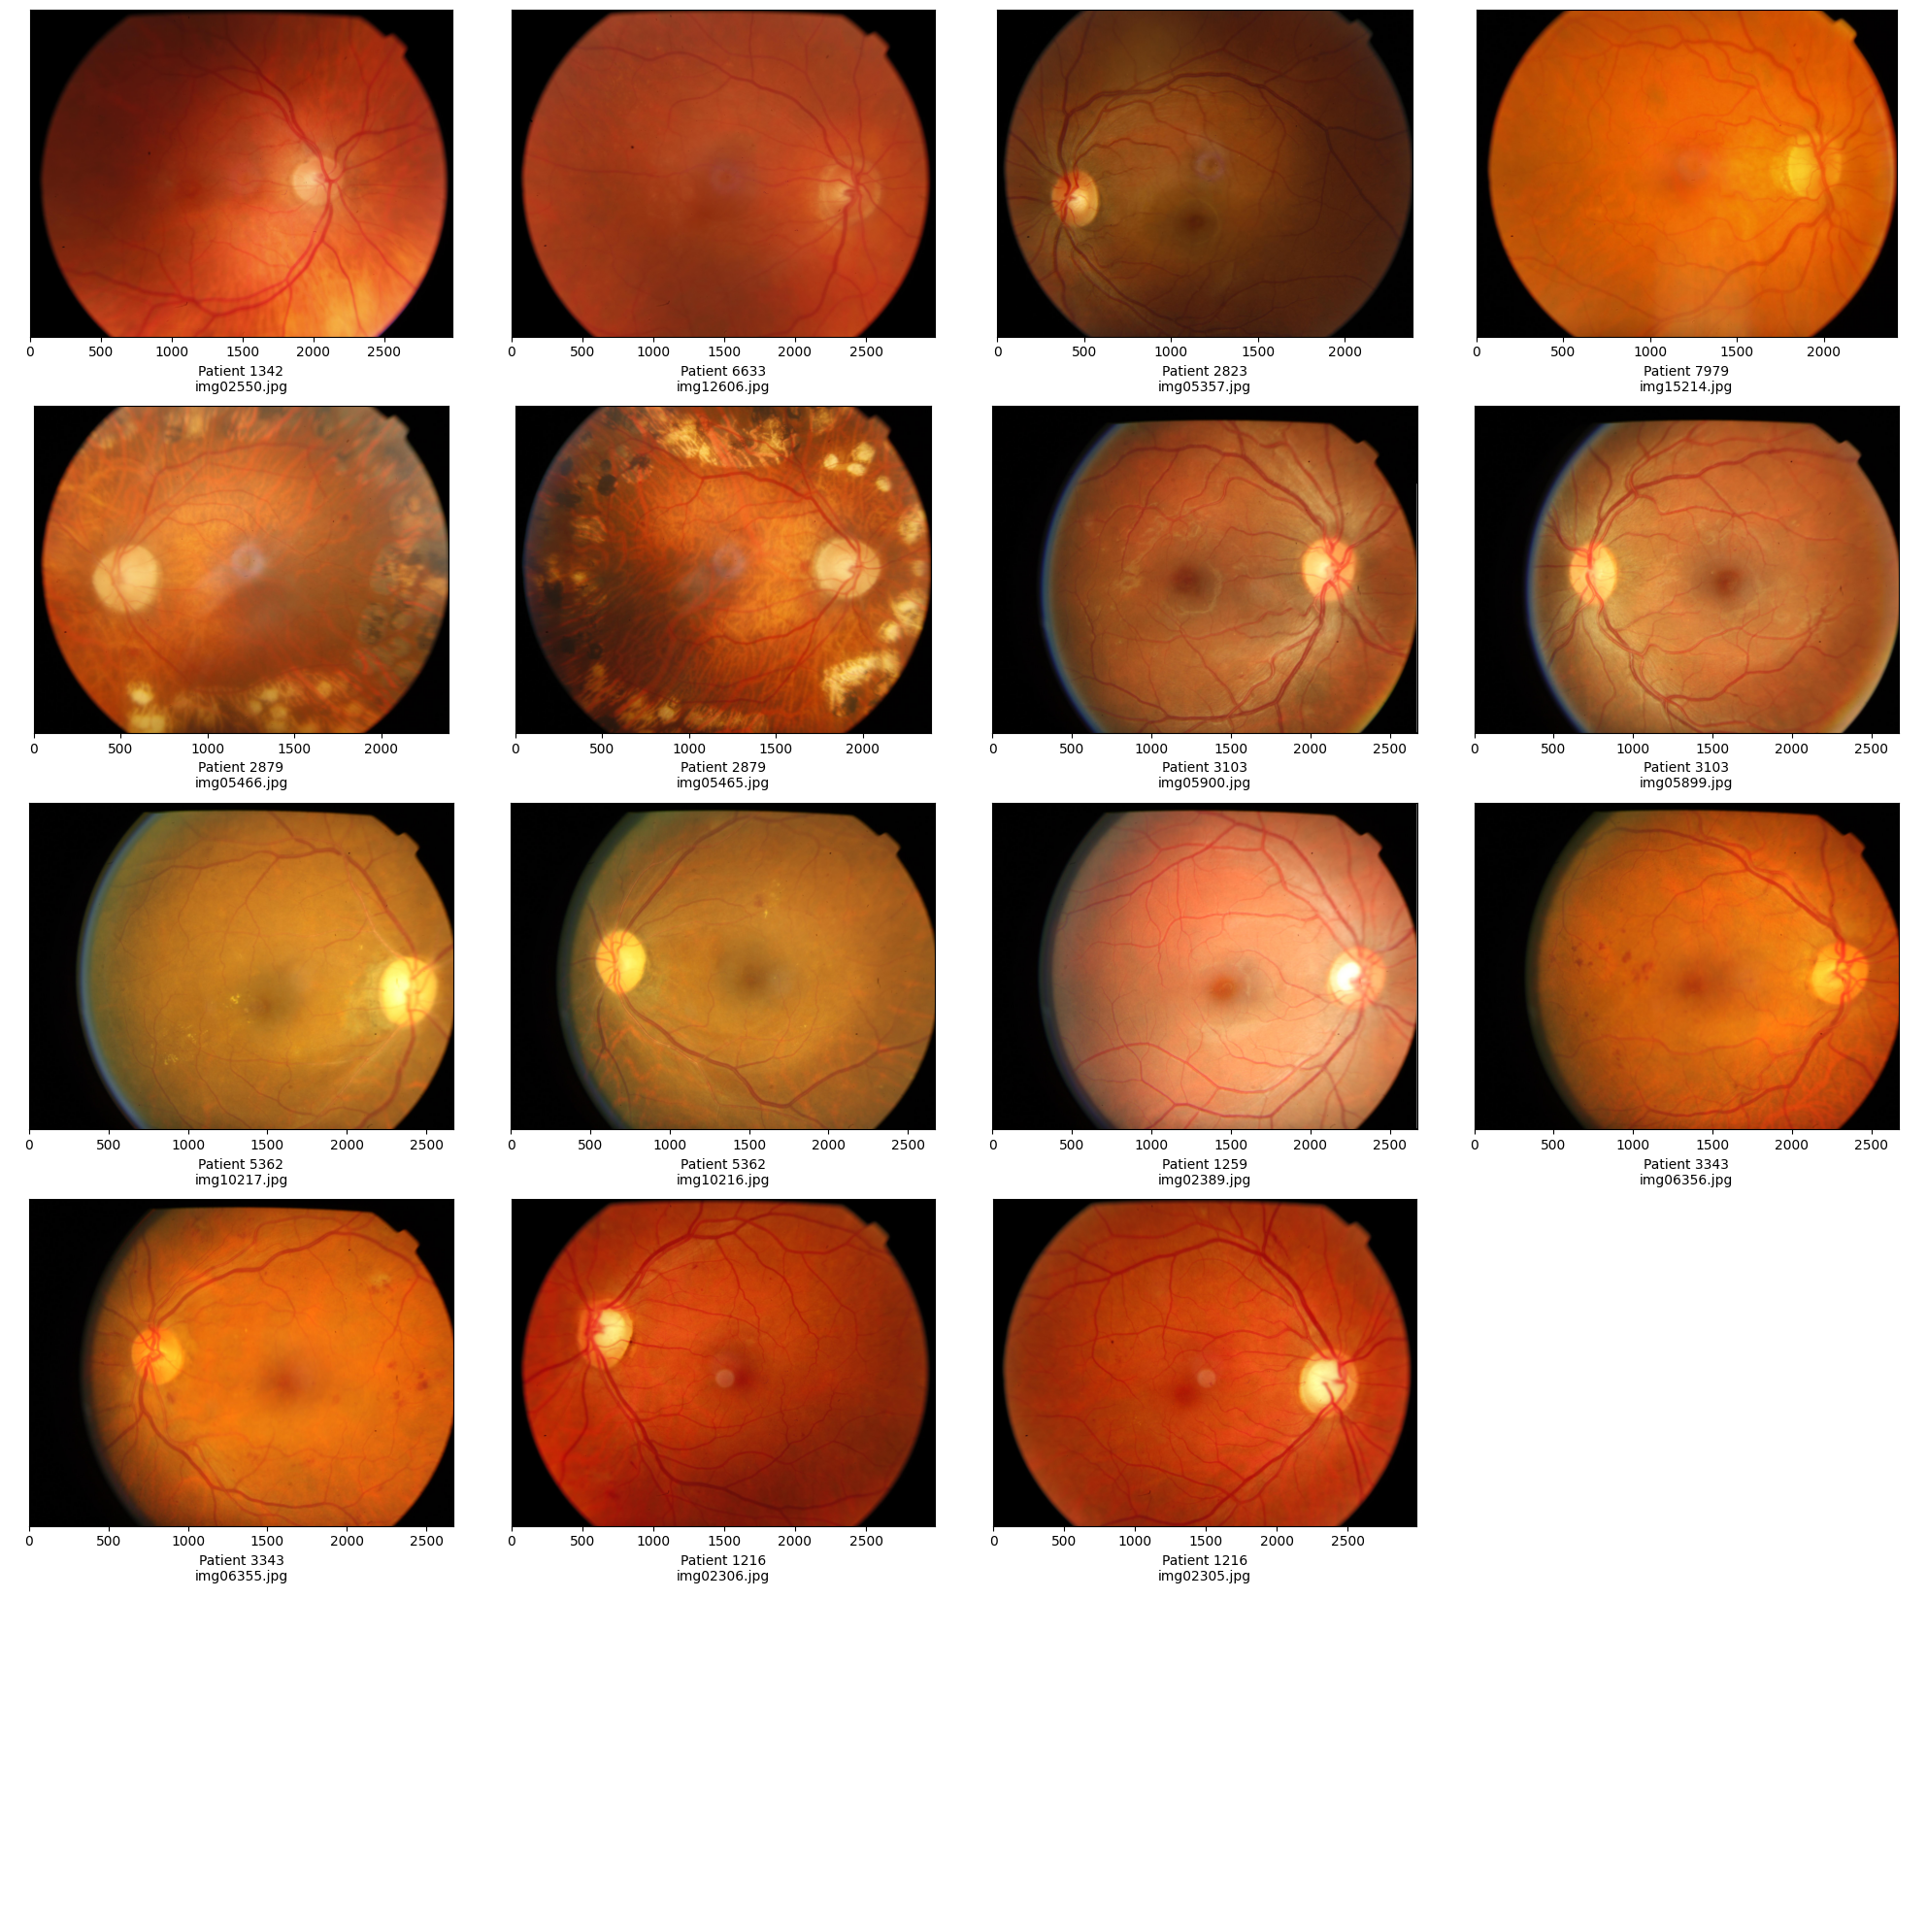

In [65]:
df = df_filtered.copy()
image_folder_path = '/Users/chandraprakashsaravanan/Documents/Chandru_Dissertation/a-brazilian-multilabel-ophthalmological-dataset-brset-1.0.0/ne_image'
display_images_for_patients(df,image_folder_path)